<a href="https://colab.research.google.com/github/kariidb/intr_2026_trabajo_final/blob/main/tarea_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

clasificación binaria supervisada: predecir si una masa mamaria es benigna (B) o maligna (M)

## 1. Subir el archivo a Colab

In [1]:
from google.colab import files

subido = files.upload()   # elegir Breast_cancer_dataset.csv desde el computador
nombre_archivo = list(subido.keys())[0]
print("Archivo subido:", nombre_archivo)

Saving Breast_cancer_dataset (1).csv to Breast_cancer_dataset (1).csv
Archivo subido: Breast_cancer_dataset (1).csv


## 2. Cargar el dataset


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# NA, N/A, ? y celdas vacías se interpretan como nulos
df = pd.read_csv(nombre_archivo, na_values=["NA", "N/A", "?", ""])

# Forzar columnas numéricas (por si alguna quedó como texto)
cols_num = df.columns.drop(["id", "diagnosis"]).tolist()
df[cols_num] = df[cols_num].apply(pd.to_numeric, errors="coerce")

print("Filas y columnas:", df.shape)
print()
print("Descriptores:")
for col in df.columns:
    print(" -", col)

Filas y columnas: (569, 32)

Descriptores:
 - id
 - diagnosis
 - radius_mean
 - texture_mean
 - perimeter_mean
 - area_mean
 - smoothness_mean
 - compactness_mean
 - concavity_mean
 - concave points_mean
 - symmetry_mean
 - fractal_dimension_mean
 - radius_se
 - texture_se
 - perimeter_se
 - area_se
 - smoothness_se
 - compactness_se
 - concavity_se
 - concave points_se
 - symmetry_se
 - fractal_dimension_se
 - radius_worst
 - texture_worst
 - perimeter_worst
 - area_worst
 - smoothness_worst
 - compactness_worst
 - concavity_worst
 - concave points_worst
 - symmetry_worst
 - fractal_dimension_worst


In [ ]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
print("Tipos de dato:")
print(df.dtypes.value_counts())
print()
print("Columnas no numéricas:", df.select_dtypes(exclude="number").columns.tolist())

Tipos de dato:
float64    30
int64       1
object      1
Name: count, dtype: int64

Columnas no numéricas: ['diagnosis']


In [ ]:
# Balance de clases (B = benigno, M = maligno)
conteo = df["diagnosis"].value_counts()
porcentaje = df["diagnosis"].value_counts(normalize=True) * 100
print(pd.DataFrame({"n": conteo, "%": porcentaje.round(1)}))

             n     %
diagnosis           
B          357  62.7
M          212  37.3


## 3.1 Valores vacíos (NaN) por descriptor

In [ ]:
import pandas as pd
import numpy as np

# 1. Cargar (NA se interpreta como nulo)
df = pd.read_csv(nombre_archivo, na_values=["NA", "N/A", "?", ""])

# 2. Forzar columnas numéricas (por si alguna quedó como texto)
cols_num = df.columns.drop(["id", "diagnosis"])
df[cols_num] = df[cols_num].apply(pd.to_numeric, errors="coerce")

# 3. Diagnóstico de datos faltantes ANTES
faltantes = df.isna().sum()
print("Total de nulos:", faltantes.sum())
print(faltantes[faltantes > 0].sort_values(ascending=False))
print("Filas con al menos un nulo:", df.isna().any(axis=1).sum())

Total de nulos: 49
radius_se                  4
smoothness_mean            3
symmetry_mean              3
fractal_dimension_mean     3
area_worst                 3
concavity_worst            3
concave points_se          3
perimeter_mean             2
concave points_worst       2
fractal_dimension_se       2
concave points_mean        2
texture_se                 2
symmetry_se                2
concavity_se               2
compactness_se             2
area_se                    2
radius_worst               2
concavity_mean             1
texture_mean               1
perimeter_se               1
smoothness_worst           1
perimeter_worst            1
symmetry_worst             1
fractal_dimension_worst    1
dtype: int64
Filas con al menos un nulo: 42


## 3.2 Splitting


In [ ]:
from sklearn.model_selection import train_test_split

X = df[cols_num].copy()                      # descriptores con NaN (sin imputar); se excluye id
y = df["diagnosis"].map({"B": 0, "M": 1})    # M = 1 (clase positiva)

# Paso 1: 80 % train / 20 % temporal
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42)

# Paso 2: el 20 % temporal se divide en mitades -> 10 % validación / 10 % test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42)

print("Train:", X_train.shape, "  Validación:", X_val.shape, "  Test:", X_test.shape)
print()

resumen = pd.DataFrame({
    "n":   [len(y), len(y_train), len(y_val), len(y_test)],
    "% del total": [100, len(y_train) / len(y) * 100, len(y_val) / len(y) * 100, len(y_test) / len(y) * 100],
    "B":   [(y == 0).sum(), (y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "M":   [(y == 1).sum(), (y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()],
    "% M": [y.mean() * 100, y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
    "NaN": [X.isna().sum().sum(), X_train.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum()],
}, index=["Total", "Train", "Validación", "Test"]).round(1)
print(resumen)

# Verificación: ningún caso se repite entre conjuntos
print()
print("Train ∩ Val: ", len(set(X_train.index) & set(X_val.index)))
print("Train ∩ Test:", len(set(X_train.index) & set(X_test.index)))
print("Val ∩ Test:  ", len(set(X_val.index) & set(X_test.index)))

Train: (455, 30)   Validación: (57, 30)   Test: (57, 30)

              n  % del total    B    M   % M  NaN
Total       569        100.0  357  212  37.3   49
Train       455         80.0  285  170  37.4   37
Validación   57         10.0   36   21  36.8    8
Test         57         10.0   36   21  36.8    4

Train ∩ Val:  0
Train ∩ Test: 0
Val ∩ Test:   0


4. IMPUTACION DE LOS DATOS FALTANTES

In [ ]:
from sklearn.impute import SimpleImputer

# Filtrar cols_num para excluir 'Unnamed: 32' si existe
cols_num = [c for c in cols_num if c != 'Unnamed: 32']

imputador = SimpleImputer(strategy="median")
imputador.fit(X_train[cols_num])                       # aprende las medianas SOLO con train

X_train_imp = pd.DataFrame(imputador.transform(X_train[cols_num]), columns=cols_num, index=X_train.index)
X_val_imp   = pd.DataFrame(imputador.transform(X_val[cols_num]),   columns=cols_num, index=X_val.index)
X_test_imp  = pd.DataFrame(imputador.transform(X_test[cols_num]),  columns=cols_num, index=X_test.index)

print("Nulos restantes -> train:", X_train_imp.isna().sum().sum(),
      " val:", X_val_imp.isna().sum().sum(),
      " test:", X_test_imp.isna().sum().sum())

# Medianas usadas (aprendidas en train) para las variables que tenían NaN
medianas = pd.Series(imputador.statistics_, index=cols_num)
cols_con_nan = [col for col in X_train.columns[X_train.isna().any()] if col != 'Unnamed: 32']
print()
if cols_con_nan:
    print("Medianas de train usadas para imputar:")
    print(medianas[cols_con_nan].round(4))
else:
    print("No se encontraron variables con valores nulos (excluyendo 'Unnamed: 32') para imputar.")

Nulos restantes -> train: 0  val: 0  test: 0

Medianas de train usadas para imputar:
texture_mean                18.9050
perimeter_mean              86.2400
smoothness_mean              0.0955
concavity_mean               0.0596
concave points_mean          0.0333
symmetry_mean                0.1798
fractal_dimension_mean       0.0613
radius_se                    0.3270
texture_se                   1.1390
area_se                     24.8300
compactness_se               0.0202
concavity_se                 0.0259
concave points_se            0.0109
symmetry_se                  0.0187
radius_worst                14.9700
perimeter_worst             97.6200
area_worst                 682.0000
smoothness_worst             0.1311
concavity_worst              0.2298
concave points_worst         0.1011
symmetry_worst               0.2824
fractal_dimension_worst      0.0801
dtype: float64


In [ ]:
# Comparar estadísticas de train antes / después de imputar
cols_ejemplo = ["radius_mean", "texture_mean", "radius_se", "area_worst"]
print(pd.concat(
    {"antes":   X_train[cols_ejemplo].describe().loc[["mean", "50%", "std"]],
     "despues": X_train_imp[cols_ejemplo].describe().loc[["mean", "50%", "std"]]},
    axis=1).round(4))

           antes                                       despues               \
     radius_mean texture_mean radius_se area_worst radius_mean texture_mean   
mean     14.1661      19.4221    0.4093   890.9692     14.1661      19.4209   
50%      13.3400      18.9050    0.3270   682.0000     13.3400      18.9050   
std       3.5791       4.2944    0.2889   582.9260      3.5791       4.2897   

                           
     radius_se area_worst  
mean    0.4087   890.5099  
50%     0.3270   682.0000  
std     0.2880   582.3661  


¿Esta comparación es suficiente para acreditar que se hizo una imputacion de manera correcta?

In [ ]:
# Armar los tres conjuntos limpios (con id y diagnosis) y guardarlos
def armar(X_imp, y_set):
    d = X_imp.copy()
    d.insert(0, "diagnosis", y_set.map({0: "B", 1: "M"}))
    d.insert(0, "id", df.loc[X_imp.index, "id"])
    return d

df_train = armar(X_train_imp, y_train)
df_val   = armar(X_val_imp,   y_val)
df_test  = armar(X_test_imp,  y_test)

df_train.to_csv("bc_train.csv", index=False)
df_val.to_csv("bc_val.csv",     index=False)
df_test.to_csv("bc_test.csv",   index=False)

print("train:", df_train.shape, " val:", df_val.shape, " test:", df_test.shape)

train: (455, 32)  val: (57, 32)  test: (57, 32)


In [ ]:
# Descargar los tres CSV (opcional)
files.download("bc_train.csv")
files.download("bc_val.csv")
files.download("bc_test.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

EDA DEL DATASET

In [ ]:
sns.set_theme(style="whitegrid")
colores = {"B": "#4C78A8", "M": "#E45756"}   # B = benigno, M = maligno

cols_mean  = [c for c in cols_num if c.endswith("_mean")]
cols_se    = [c for c in cols_num if c.endswith("_se")]
cols_worst = [c for c in cols_num if c.endswith("_worst")]

print("Variables continuas:", len(cols_num))
print("_mean:", len(cols_mean), " _se:", len(cols_se), " _worst:", len(cols_worst))

Variables continuas: 30
_mean: 10  _se: 10  _worst: 10


GRAFICO DE BARRAS PARA VARIABLES CATEGORICAS

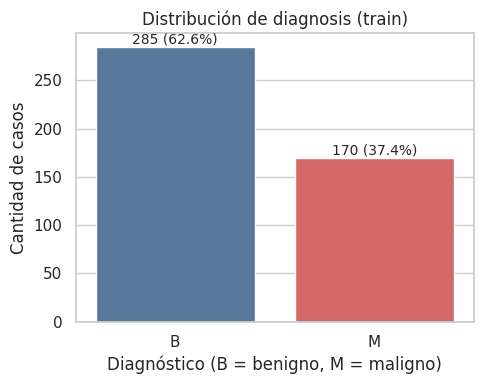

In [ ]:
conteo = df_train["diagnosis"].value_counts()

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df_train, x="diagnosis", order=conteo.index,
              hue="diagnosis", palette=colores, legend=False, ax=ax)

# Etiquetas con cantidad y porcentaje
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{int(h)} ({h/len(df_train):.1%})",
                (p.get_x() + p.get_width()/2, h),
                ha="center", va="bottom", fontsize=10)

ax.set_title("Distribución de diagnosis (train)")
ax.set_xlabel("Diagnóstico (B = benigno, M = maligno)")
ax.set_ylabel("Cantidad de casos")
plt.tight_layout()
plt.show()

BOXPLOT PARA VARIABLES CONTINUAS

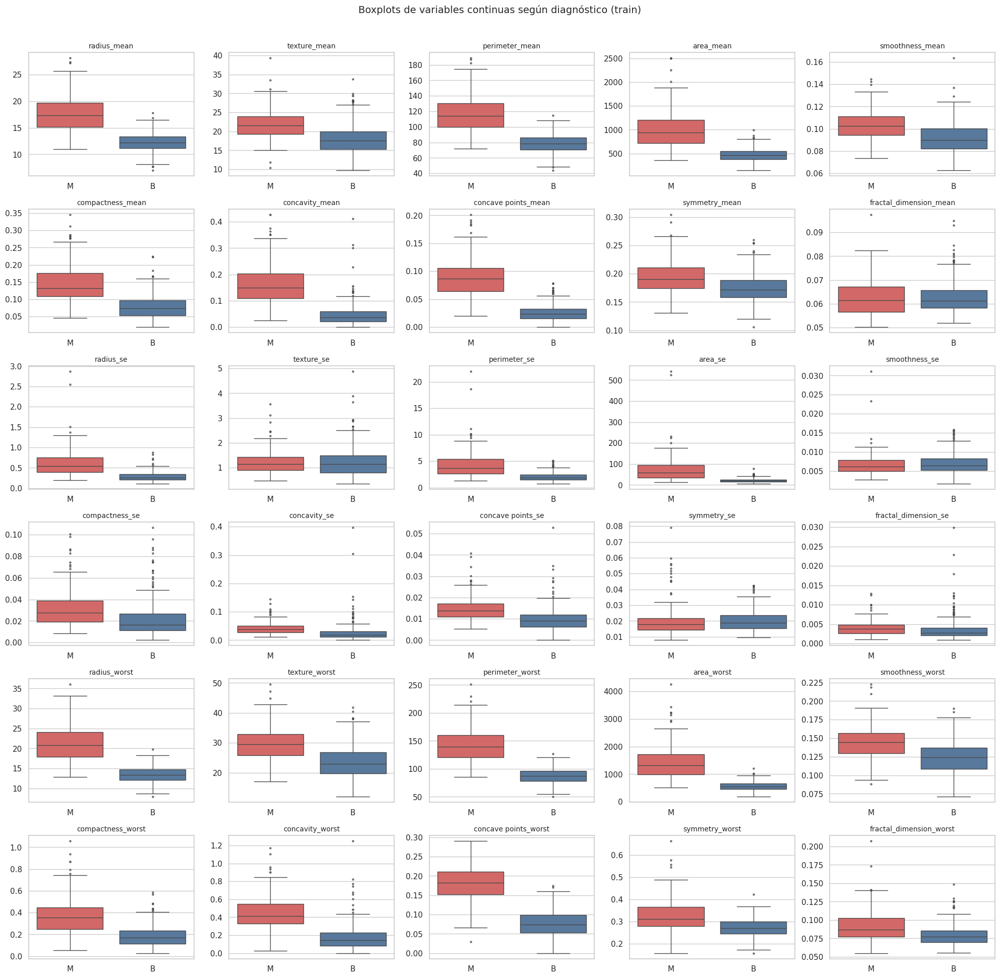

In [ ]:
n_cols = 5
n_rows = int(np.ceil(len(cols_num) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3.2 * n_rows))
axes = axes.flatten()

for ax, var in zip(axes, cols_num):
    sns.boxplot(data=df_train, x="diagnosis", y=var, hue="diagnosis",
                palette=colores, legend=False, fliersize=2, ax=ax)
    ax.set_title(var, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

# Ocultar ejes sobrantes
for ax in axes[len(cols_num):]:
    ax.set_visible(False)

fig.suptitle("Boxplots de variables continuas según diagnóstico (train)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

COLUMNAS CON LAS VAIRABLE CONTINUAS

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white")
colores = {"B": "#4C78A8", "M": "#E45756"}   # B = benigno, M = maligno

cols_num   = df_train.columns.drop(["id", "diagnosis"]).tolist()
cols_mean  = [c for c in cols_num if c.endswith("_mean")]
cols_se    = [c for c in cols_num if c.endswith("_se")]
cols_worst = [c for c in cols_num if c.endswith("_worst")]

MATRIZ DE SCATTER PLOTS POR GRUPO (PAIR PLOTS)

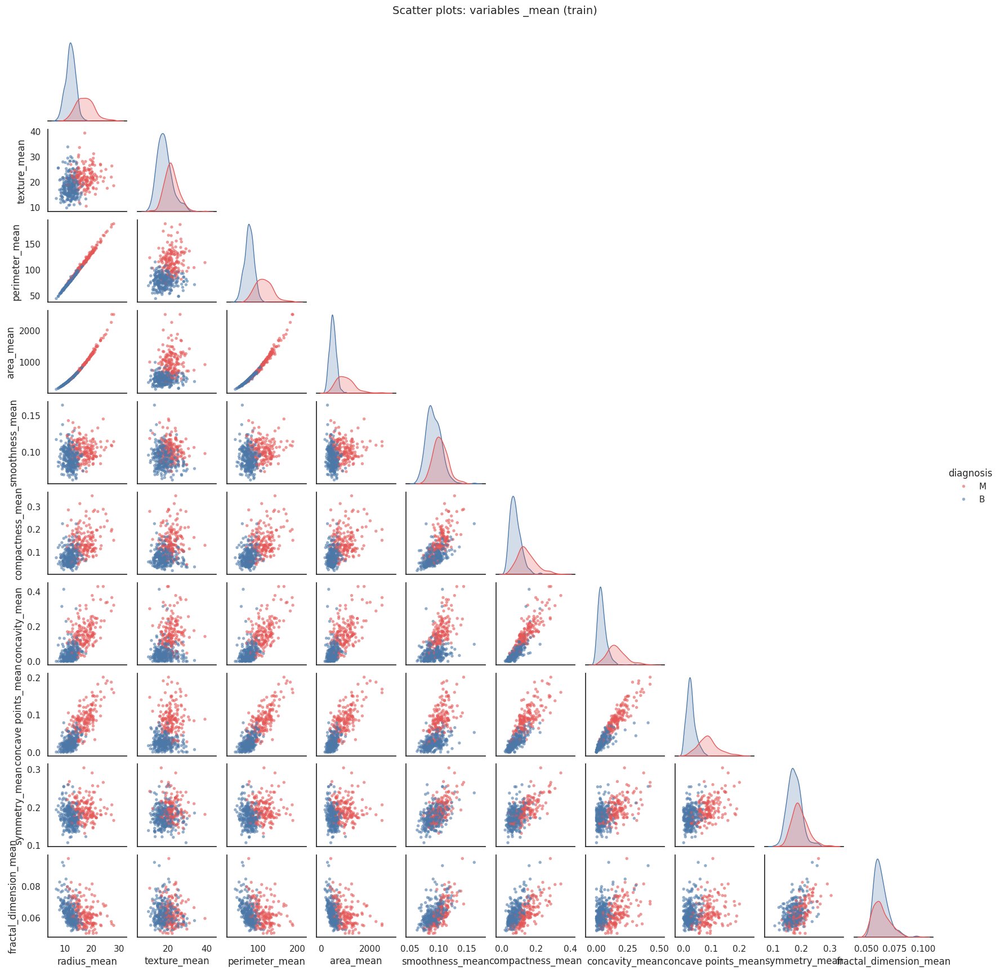

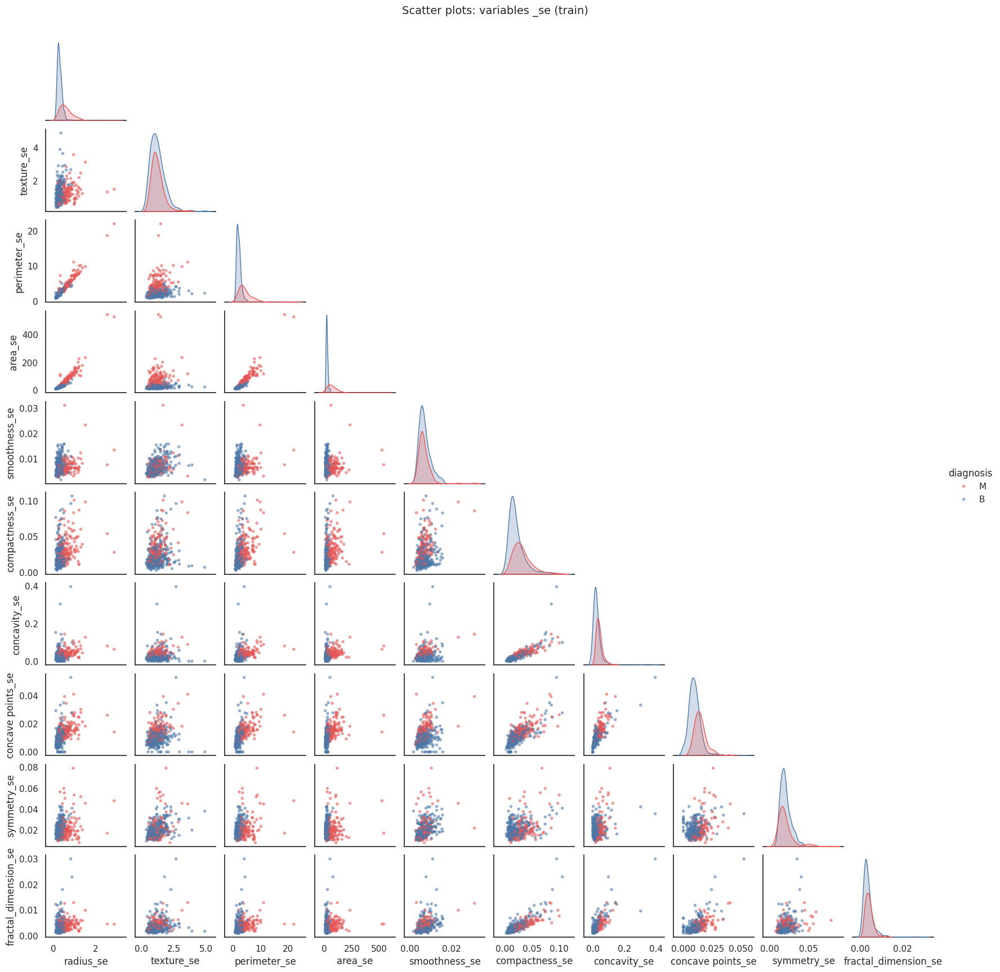

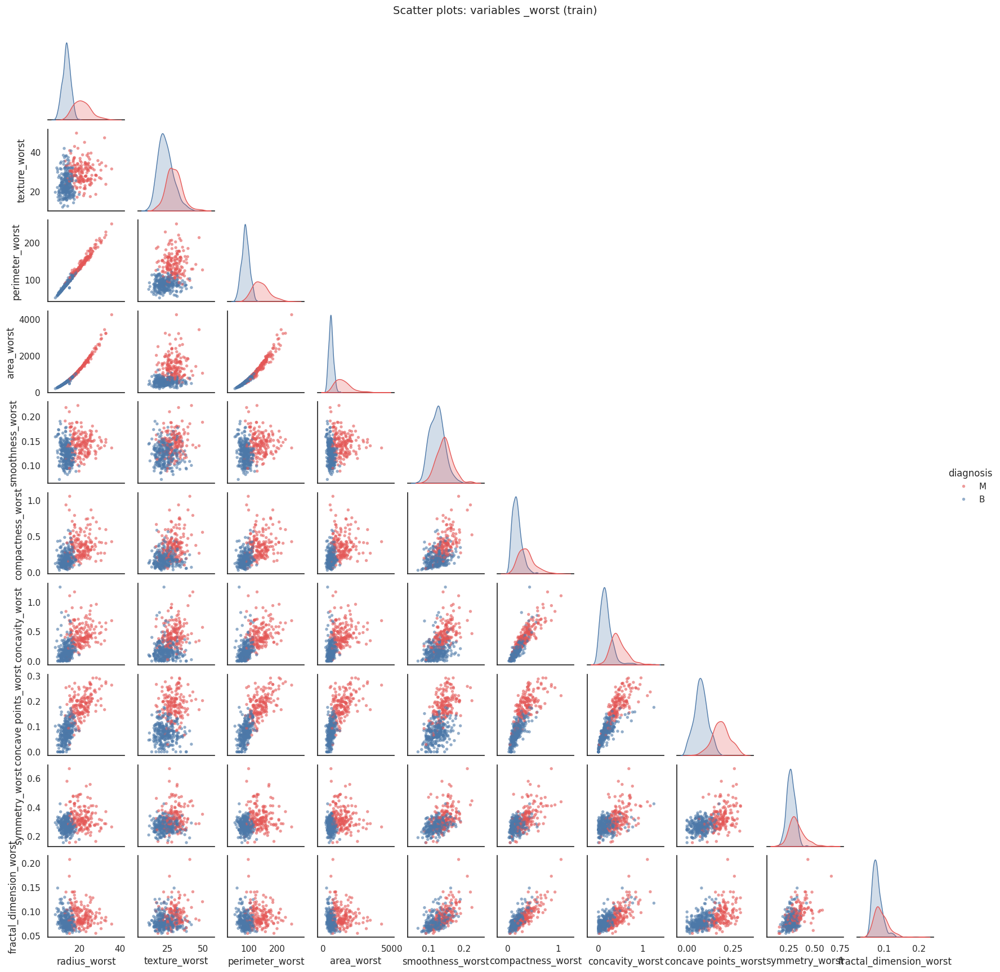

In [ ]:
def pairplot_grupo(columnas, titulo):
    g = sns.pairplot(df_train, vars=columnas, hue="diagnosis", palette=colores,
                     diag_kind="kde", corner=True, height=1.7,
                     plot_kws={"s": 15, "alpha": 0.6, "edgecolor": "none"})
    g.figure.suptitle(titulo, y=1.02, fontsize=14)
    plt.show()

pairplot_grupo(cols_mean,  "Scatter plots: variables _mean (train)")
pairplot_grupo(cols_se,    "Scatter plots: variables _se (train)")
pairplot_grupo(cols_worst, "Scatter plots: variables _worst (train)")

LOS PARES DE DESCRIPTORES MAS CORRELACIONADOS

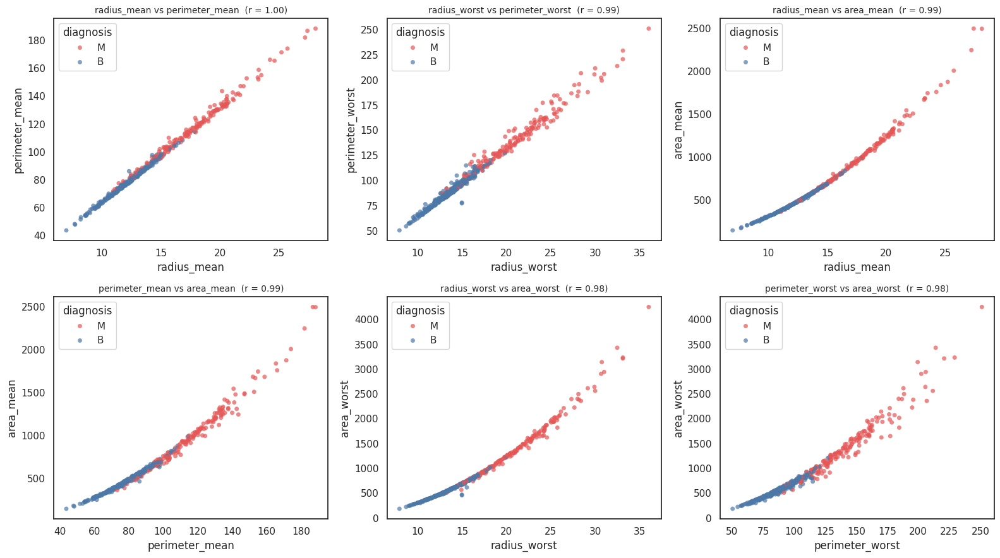

In [ ]:
corr_abs = df_train[cols_num].corr().abs()
pares = (corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
                 .stack().sort_values(ascending=False))

top_n = 6
top_pares = pares.head(top_n).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, (x, y_var) in zip(axes, top_pares):
    sns.scatterplot(data=df_train, x=x, y=y_var, hue="diagnosis", palette=colores,
                    s=25, alpha=0.7, edgecolor="none", ax=ax)
    r = df_train[[x, y_var]].corr().iloc[0, 1]
    ax.set_title(f"{x} vs {y_var}  (r = {r:.2f})", fontsize=10)
plt.tight_layout()
plt.show()

4. SCATTER PLOT DE UN PAR ESPECIFICO


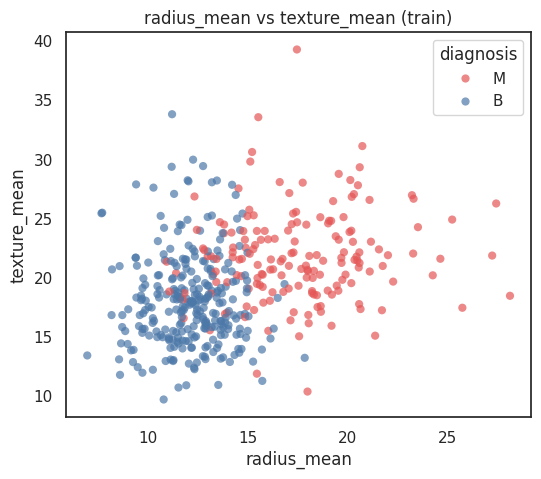

In [ ]:
x, y_var = "radius_mean", "texture_mean"

plt.figure(figsize=(6, 5))
sns.scatterplot(data=df_train, x=x, y=y_var, hue="diagnosis", palette=colores,
                s=35, alpha=0.7, edgecolor="none")
plt.title(f"{x} vs {y_var} (train)")
plt.show()

HEATMAP DE CORRELACION ENTRE TODAS LAS VARIABLES CONTINUAS

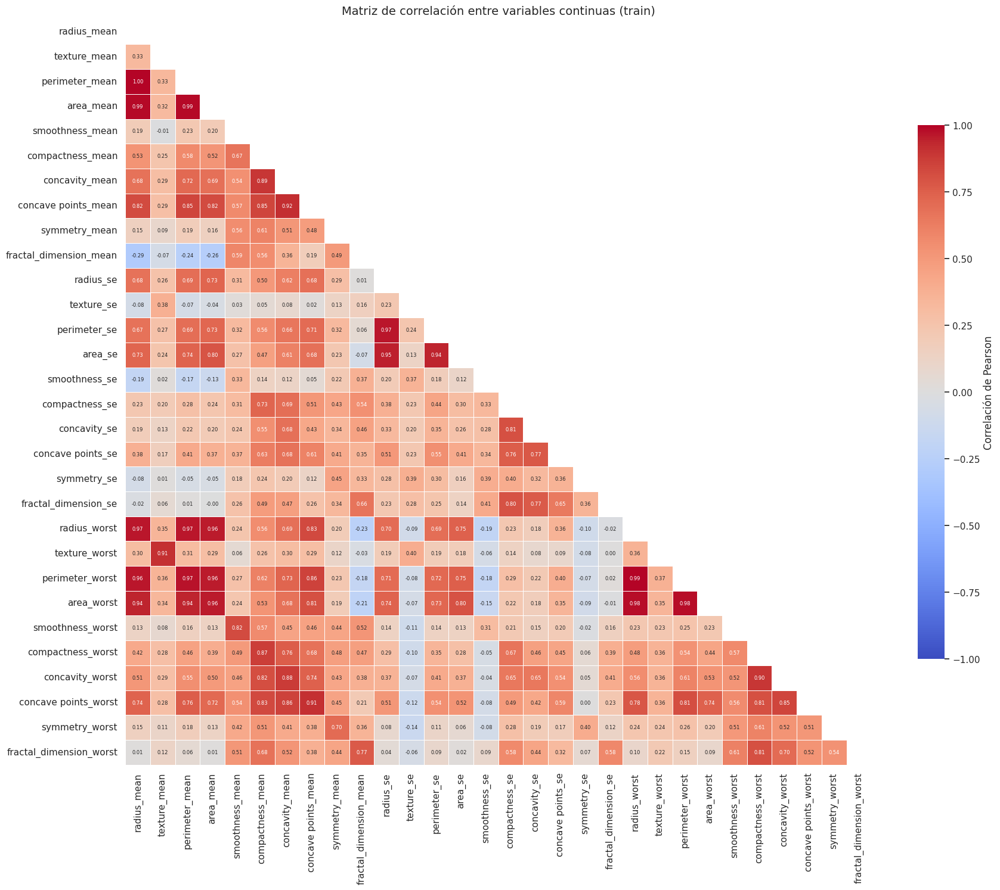

In [ ]:
# Matriz de correlación de Pearson (train)
corr = df_train[cols_num].corr(method="pearson")

# Máscara para mostrar solo el triángulo inferior (evita duplicados)
mascara = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(18, 15))
sns.heatmap(corr, mask=mascara, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 6},
            linewidths=0.4, square=True,
            cbar_kws={"shrink": 0.7, "label": "Correlación de Pearson"})
plt.title("Matriz de correlación entre variables continuas (train)", fontsize=14)
plt.tight_layout()
plt.show()

CORRELACION DE CADA VARIABLE CON EL DIAGNOSTICO

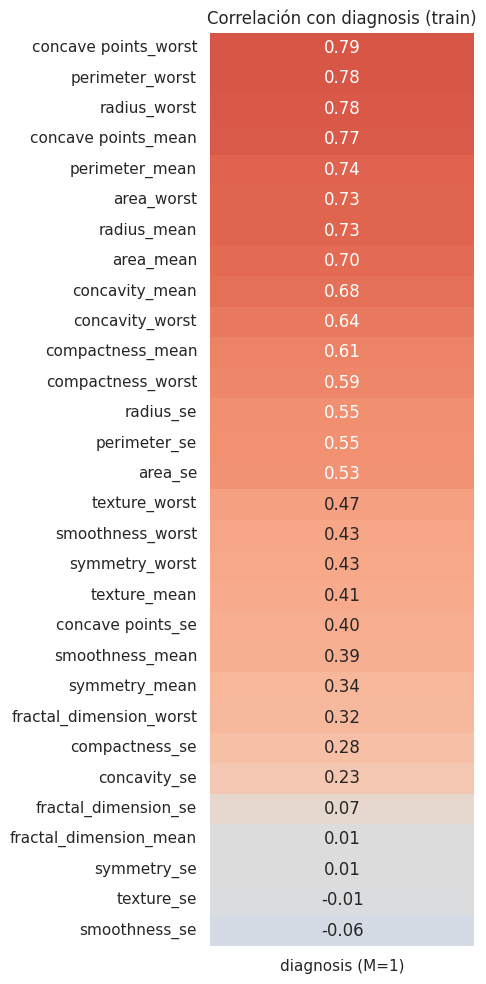

In [ ]:
df_corr = df_train.copy()
df_corr["diagnosis_num"] = df_corr["diagnosis"].map({"B": 0, "M": 1})

corr_diag = (df_corr[cols_num + ["diagnosis_num"]].corr()["diagnosis_num"]
             .drop("diagnosis_num").sort_values(ascending=False))

plt.figure(figsize=(5, 10))
sns.heatmap(corr_diag.to_frame("diagnosis (M=1)"), cmap="coolwarm",
            vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", cbar=False)
plt.title("Correlación con diagnosis (train)")
plt.tight_layout()
plt.show()

PARES CON CORRELACION MUY ALTA

In [ ]:
umbral = 0.90

triangulo = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
altas = (triangulo.stack().rename("r").reset_index()
         .rename(columns={"level_0": "var_1", "level_1": "var_2"}))
altas = altas[altas["r"].abs() >= umbral].sort_values("r", key=abs, ascending=False)

print(f"Pares con |r| >= {umbral}: {len(altas)}")
altas.round(4)

Pares con |r| >= 0.9: 21


,var_1,var_2,r
1,radius_mean,perimeter_mean,0.9977
391,radius_worst,perimeter_worst,0.9929
2,radius_mean,area_mean,0.9867
57,perimeter_mean,area_mean,0.9859
392,radius_worst,area_worst,0.9827
407,perimeter_worst,area_worst,0.9767
76,perimeter_mean,perimeter_worst,0.9698
19,radius_mean,radius_worst,0.9685
74,perimeter_mean,radius_worst,0.9683
246,radius_se,perimeter_se,0.9661


Selección de las variables con correlación alta

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

colores = {"B": "#4C78A8", "M": "#E45756"}
umbral = 0.90          # puedes cambiarlo (0.85, 0.80...)

# La misma matriz de correlación (train) que ya calculaste
corr = df_train[cols_num].corr(method="pearson")

# Cuántas correlaciones |r| >= umbral tiene cada variable (sin contar consigo misma)
sin_diag = corr.abs().where(~np.eye(len(corr), dtype=bool))
n_altas = (sin_diag >= umbral).sum()

vars_corr = n_altas[n_altas > 0].sort_values(ascending=False).index.tolist()
print(f"{len(vars_corr)} variables con al menos una correlación |r| >= {umbral}:")
print(vars_corr)


14 variables con al menos una correlación |r| >= 0.9:
['radius_mean', 'perimeter_mean', 'area_mean', 'area_worst', 'perimeter_worst', 'radius_worst', 'area_se', 'perimeter_se', 'concave points_mean', 'radius_se', 'concavity_mean', 'texture_mean', 'texture_worst', 'concave points_worst']


Estandarización y PCA

In [ ]:
X_sel = df_train[vars_corr]
y_train = df_train["diagnosis"]

scaler = StandardScaler()
X_sc = scaler.fit_transform(X_sel)

pca = PCA(random_state=42)
pca.fit(X_sc)

var = pca.explained_variance_ratio_
acum = np.cumsum(var)

tabla = pd.DataFrame({
    "Componente": [f"PC{i+1}" for i in range(len(var))],
    "Varianza explicada (%)": var * 100,
    "Acumulada (%)": acum * 100})
display(tabla.round(2))

for u in (0.90, 0.95, 0.99):
    print(f"Componentes para explicar {u:.0%}: {int(np.argmax(acum >= u)) + 1}")

,Componente,Varianza explicada (%),Acumulada (%)
0,PC1,71.72,71.72
1,PC2,12.09,83.81
2,PC3,7.52,91.33
3,PC4,5.48,96.80
4,PC5,1.16,97.97
5,PC6,0.59,98.56
6,PC7,0.40,98.95
7,PC8,0.39,99.34
8,PC9,0.30,99.65
9,PC10,0.23,99.87


Componentes para explicar 90%: 3
Componentes para explicar 95%: 4
Componentes para explicar 99%: 8


Resumen EDA

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# Etiquetas numéricas (M = 1). Se definen de nuevo porque la celda del PCA anterior
# dejó y_train como texto (B/M).
y_tr = df_train["diagnosis"].map({"B": 0, "M": 1}).values
y_va = df_val["diagnosis"].map({"B": 0, "M": 1}).values

cols_num   = df_train.columns.drop(["id", "diagnosis"]).tolist()
cols_mean  = [c for c in cols_num if c.endswith("_mean")]
cols_se    = [c for c in cols_num if c.endswith("_se")]
cols_worst = [c for c in cols_num if c.endswith("_worst")]

# Carpeta y formato de figuras
carpeta_fig = "figuras_fe"
os.makedirs(carpeta_fig, exist_ok=True)
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["figure.titleweight"] = "bold"

def guardar(fig, nombre):
    fig.savefig(os.path.join(carpeta_fig, nombre + ".png"), dpi=300, bbox_inches="tight")
    fig.savefig(os.path.join(carpeta_fig, nombre + ".pdf"), bbox_inches="tight")
    print("Guardada:", nombre)

In [ ]:
## 5.1 Tabla diagnóstica por descriptor
- **AUC univariada**: qué tan bien separa B de M cada variable sola (0,5 = nada; 1 = perfecto).
- **skewness**: asimetría (|valor| > 1 = fuerte).
- **n_outliers**: casos fuera de 1,5 × IQR.
- **n_r_alta**: con cuántas variables tiene |r| ≥ 0,90.

SyntaxError: invalid character '×' (U+00D7) (2898539794.py, line 4)

In [ ]:
corr_tr = df_train[cols_num].corr()

filas = []
for var in cols_num:
    x = df_train[var]

    auc = roc_auc_score(y_tr, x)
    auc_sep = max(auc, 1 - auc)          # separación sin importar el sentido

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    n_out = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()

    n_r_alta = (corr_tr[var].abs() >= 0.90).sum() - 1   # se resta la propia variable

    if auc_sep >= 0.90:
        senal = "alta"
    elif auc_sep >= 0.70:
        senal = "media"
    elif auc_sep >= 0.60:
        senal = "baja"
    else:
        senal = "nula"

    filas.append([var, var.split("_")[-1], round(auc_sep, 3), senal,
                  round(x.skew(), 2), n_out, n_r_alta,
                  round(x[y_tr == 0].median(), 4), round(x[y_tr == 1].median(), 4)])

tabla_eda = pd.DataFrame(filas, columns=["descriptor", "bloque", "AUC", "señal", "skewness",
                                         "n_outliers", "n_r_alta", "mediana_B", "mediana_M"])
tabla_eda = tabla_eda.sort_values("AUC", ascending=False).reset_index(drop=True)
pd.set_option("display.max_rows", 50)
tabla_eda

,descriptor,bloque,AUC,señal,skewness,n_outliers,n_r_alta,mediana_B,mediana_M
0,perimeter_worst,worst,0.974,alta,1.14,12,5,87.0000,139.3500
1,radius_worst,worst,0.969,alta,1.12,11,5,13.3700,20.8500
2,area_worst,worst,0.968,alta,1.90,21,5,547.8000,1317.5000
3,concave points_worst,worst,0.963,alta,0.50,0,1,0.0745,0.1827
4,concave points_mean,mean,0.961,alta,1.22,9,2,0.0233,0.0863
5,perimeter_mean,mean,0.945,alta,1.04,12,5,78.1800,114.3000
6,area_mean,mean,0.937,alta,1.72,20,5,460.3000,940.4500
7,radius_mean,mean,0.937,alta,0.99,11,5,12.2100,17.3850
8,concavity_mean,mean,0.933,alta,1.46,17,1,0.0371,0.1491
9,area_se,se,0.921,alta,5.50,53,2,19.9100,59.5800


In [ ]:
print("Variables con |skewness| > 1:", (tabla_eda["skewness"].abs() > 1).sum(), "de", len(cols_num))
print()
print("Señal univariada por bloque (n de variables):")
print(pd.crosstab(tabla_eda["bloque"], tabla_eda["señal"]))
print()
print("Outliers totales por bloque:")
print(tabla_eda.groupby("bloque")["n_outliers"].sum())

Variables con |skewness| > 1: 23 de 30

Señal univariada por bloque (n de variables):
señal   alta  baja  media  nula
bloque                         
mean       5     0      4     1
se         1     1      5     3
worst      5     1      4     0

Outliers totales por bloque:
bloque
mean     118
se       265
worst    114
Name: n_outliers, dtype: int64


Guardada: auc_univariada


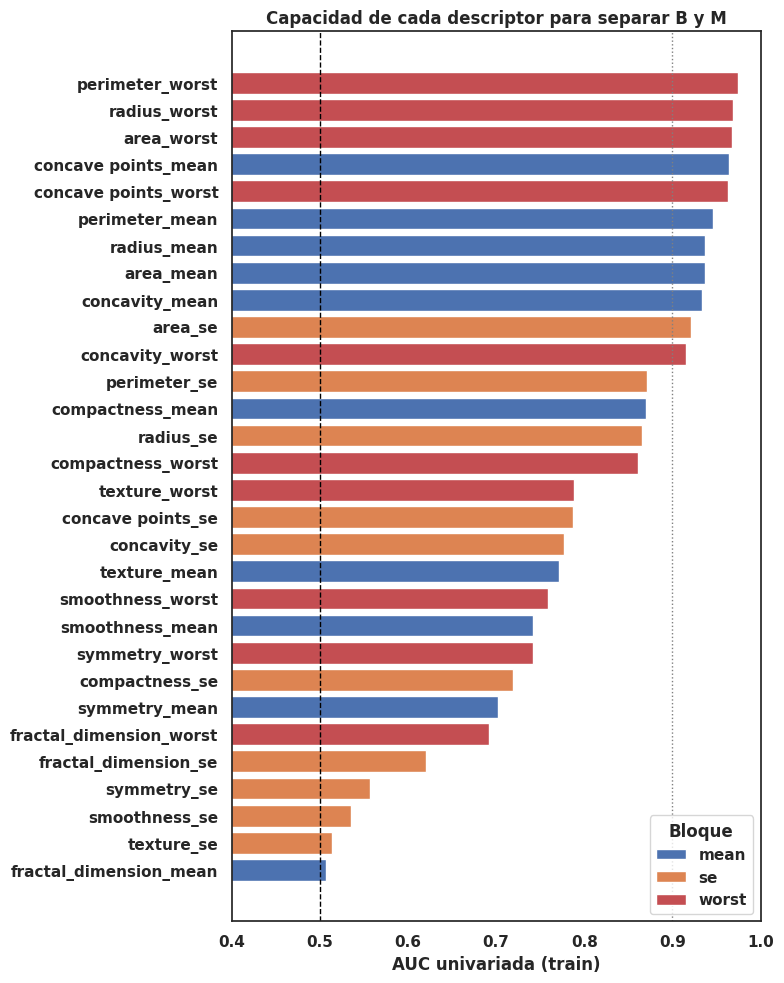

In [ ]:
# Gráfico: AUC univariada por descriptor, coloreado por bloque
color_bloque = {"mean": "#4C72B0", "se": "#DD8452", "worst": "#C44E52"}
orden = tabla_eda.sort_values("AUC")

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(orden["descriptor"], orden["AUC"],
        color=[color_bloque[b] for b in orden["bloque"]], edgecolor="white", linewidth=1)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax.axvline(0.9, color="gray", linestyle=":", linewidth=1)
ax.set_xlim(0.4, 1.0)
ax.set_xlabel("AUC univariada (train)")
ax.set_title("Capacidad de cada descriptor para separar B y M")
from matplotlib.patches import Patch
manijas = []
for b in color_bloque:
    manijas.append(Patch(facecolor=color_bloque[b], edgecolor="white", label=b))
ax.legend(handles=manijas, title="Bloque", loc="lower right")
fig.tight_layout()
guardar(fig, "auc_univariada")
plt.show()

Continuación

In [ ]:
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.decomposition import PCA

usar_yeo_johnson = True     # False = solo StandardScaler
umbral_varianza  = 0.90     # 0.90 o 0.95

bloques = {"mean": cols_mean, "se": cols_se, "worst": cols_worst}

transformadores = {}
pcas = {}
tablas_var = {}

for b in bloques:
    variables = bloques[b]

    if usar_yeo_johnson:
        prep = PowerTransformer(method="yeo-johnson", standardize=True)
    else:
        prep = StandardScaler()
    Z_tr = prep.fit_transform(df_train[variables])

    pca = PCA(random_state=42)
    pca.fit(Z_tr)

    var = pca.explained_variance_ratio_
    acum = np.cumsum(var)
    scores = pca.transform(Z_tr)

    auc_pc = []
    for i in range(len(var)):
        a = roc_auc_score(y_tr, scores[:, i])
        auc_pc.append(max(a, 1 - a))

    tablas_var[b] = pd.DataFrame({
        "Componente": ["PC" + str(i + 1) for i in range(len(var))],
        "Varianza (%)": (var * 100).round(2),
        "Acumulada (%)": (acum * 100).round(2),
        "AUC": np.round(auc_pc, 3)})

    transformadores[b] = prep
    pcas[b] = pca

    print("Bloque", b)
    print(tablas_var[b].head(6).to_string(index=False))
    print("  Componentes para 90 %:", int(np.argmax(acum >= 0.90)) + 1,
          "| para 95 %:", int(np.argmax(acum >= 0.95)) + 1)
    print()

Bloque mean
Componente  Varianza (%)  Acumulada (%)   AUC
       PC1         53.90          53.90 0.975
       PC2         25.83          79.73 0.554
       PC3          8.81          88.54 0.576
       PC4          5.48          94.02 0.515
       PC5          3.46          97.48 0.513
       PC6          1.58          99.06 0.561
  Componentes para 90 %: 4 | para 95 %: 5

Bloque se
Componente  Varianza (%)  Acumulada (%)   AUC
       PC1         51.03          51.03 0.818
       PC2         17.21          68.24 0.800
       PC3         13.93          82.17 0.575
       PC4          5.75          87.91 0.501
       PC5          5.42          93.34 0.529
       PC6          3.59          96.93 0.512
  Componentes para 90 %: 5 | para 95 %: 6

Bloque worst
Componente  Varianza (%)  Acumulada (%)   AUC
       PC1         57.90          57.90 0.974
       PC2         20.49          78.39 0.623
       PC3          8.09          86.48 0.565
       PC4          5.72          92.20 0.539
     

NameError: name 'color_bloque' is not defined

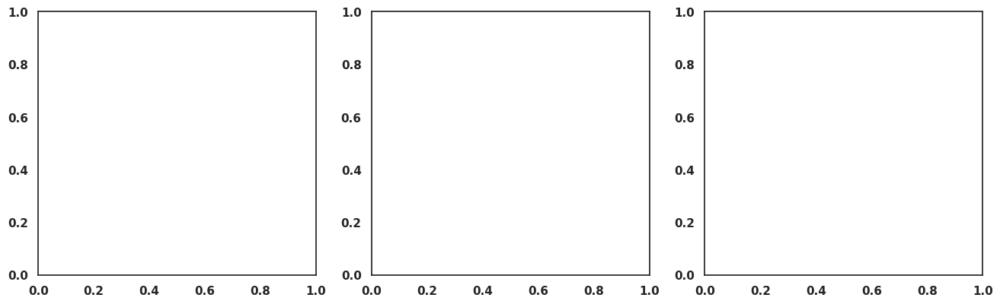

In [ ]:
# Scree plot por bloque
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
for i, b in enumerate(bloques):
    t = tablas_var[b]
    x = np.arange(1, len(t) + 1)
    ax = ejes[i]
    ax.bar(x, t["Varianza (%)"], color=color_bloque[b], edgecolor="white", linewidth=1)
    ax.plot(x, t["Acumulada (%)"], color="black", marker="o", markersize=5,
            markeredgecolor="white")
    ax.axhline(umbral_varianza * 100, color="gray", linestyle="--", linewidth=1)
    ax.set_xticks(x)
    ax.set_xlabel("Componente")
    ax.set_ylabel("Varianza explicada (%)")
    ax.set_ylim(0, 105)
    ax.set_title("Bloque _" + b)
fig.suptitle("Scree plot por bloque (train)", fontsize=14)
fig.tight_layout()
guardar(fig, "pca_bloque_scree")
plt.show()

Guardada: pca_bloque_cargas


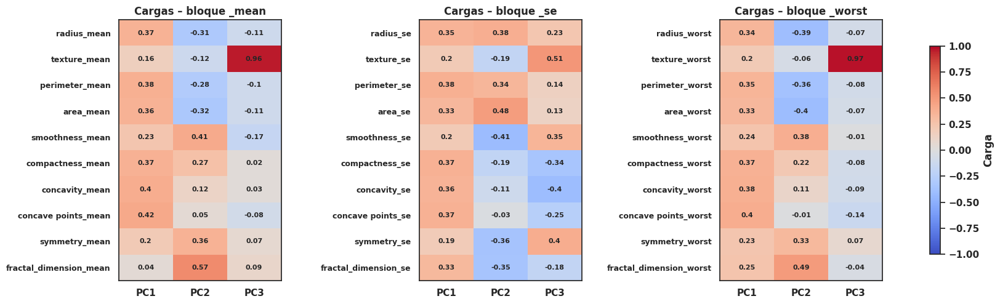

In [ ]:
# Cargas (loadings) de PC1 a PC3 por bloque: qué variables construyen cada componente
fig, ejes = plt.subplots(1, 3, figsize=(20, 5.5))
plt.subplots_adjust(wspace=0.85)
for i, b in enumerate(bloques):
    cargas = pd.DataFrame(pcas[b].components_[:3].T,
                          index=bloques[b], columns=["PC1", "PC2", "PC3"])
    ax = ejes[i]
    im = ax.imshow(cargas.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(3))
    ax.set_xticklabels(cargas.columns)
    ax.set_yticks(range(len(cargas)))
    ax.set_yticklabels(cargas.index, fontsize=9)
    for f in range(cargas.shape[0]):
        for c in range(3):
            ax.text(c, f, str(round(cargas.values[f, c], 2)), ha="center", va="center", fontsize=8)
    ax.set_title("Cargas – bloque _" + b)
fig.colorbar(im, ax=ejes, shrink=0.8, label="Carga")
guardar(fig, "pca_bloque_cargas")
plt.show()

Guardada: pca_bloque_scatter


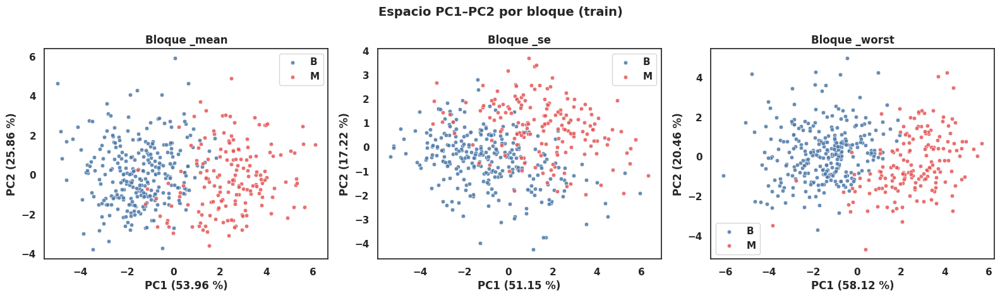

In [ ]:
# PC1 vs PC2 por bloque, coloreado por diagnóstico
col_diag = {0: "#4C78A8", 1: "#E45756"}
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.8))
for i, b in enumerate(bloques):
    S = pcas[b].transform(transformadores[b].transform(df_train[bloques[b]]))
    ax = ejes[i]
    for clase, nombre in [(0, "B"), (1, "M")]:
        m = y_tr == clase
        ax.scatter(S[m, 0], S[m, 1], s=22, c=col_diag[clase], edgecolor="white",
                   linewidth=0.5, alpha=0.85, label=nombre)
    v = tablas_var[b]["Varianza (%)"]
    ax.set_xlabel("PC1 (" + str(v[0]) + " %)")
    ax.set_ylabel("PC2 (" + str(v[1]) + " %)")
    ax.set_title("Bloque _" + b)
    ax.legend()
fig.suptitle("Espacio PC1–PC2 por bloque (train)", fontsize=14)
fig.tight_layout()
guardar(fig, "pca_bloque_scatter")
plt.show()

In [ ]:
# Construir los conjuntos reducidos con k componentes por bloque (criterio de varianza)
def scores_bloque(df_set, b, k):
    Z = transformadores[b].transform(df_set[bloques[b]])
    S = pcas[b].transform(Z)[:, :k]
    nombres = [b + "_PC" + str(i + 1) for i in range(k)]
    return pd.DataFrame(S, columns=nombres, index=df_set.index)

k_bloque = {}
for b in bloques:
    acum = tablas_var[b]["Acumulada (%)"].values / 100
    k_bloque[b] = int(np.argmax(acum >= umbral_varianza)) + 1
print("Componentes por bloque:", k_bloque, "-> total:", sum(k_bloque.values()))

partes_tr = []
partes_va = []
partes_te = []
for b in bloques:
    partes_tr.append(scores_bloque(df_train, b, k_bloque[b]))
    partes_va.append(scores_bloque(df_val,   b, k_bloque[b]))
    partes_te.append(scores_bloque(df_test,  b, k_bloque[b]))

X_train_pca = pd.concat(partes_tr, axis=1)
X_val_pca   = pd.concat(partes_va, axis=1)
X_test_pca  = pd.concat(partes_te, axis=1)

print("train:", X_train_pca.shape, " val:", X_val_pca.shape, " test:", X_test_pca.shape)

# Correlación entre componentes de bloques distintos (dentro de un bloque es 0 por construcción)
c = X_train_pca.corr().abs().where(~np.eye(X_train_pca.shape[1], dtype=bool))
print("Máxima |r| entre componentes:", round(c.max().max(), 3))
X_train_pca.head()

Componentes por bloque: {'mean': 4, 'se': 5, 'worst': 4} -> total: 13
train: (455, 13)  val: (57, 13)  test: (57, 13)
Máxima |r| entre componentes: 0.929


,mean_PC1,mean_PC2,mean_PC3,mean_PC4,se_PC1,se_PC2,se_PC3,se_PC4,se_PC5,worst_PC1,worst_PC2,worst_PC3,worst_PC4
10,-0.253671,-2.300862,0.669146,-0.278485,-1.175869,1.652949,0.450357,0.618800,0.157787,0.527420,-1.171575,1.197743,0.367245
170,-1.045272,0.632920,-1.810867,0.866797,-1.541935,-0.440335,-0.106379,-1.249358,-0.479877,-1.786661,0.039161,-1.561422,0.961440
407,-1.197753,-0.970195,0.851938,-0.520447,2.554421,-0.869497,-0.082143,0.672011,0.894703,-1.340300,-0.675108,0.458808,-0.813817
430,2.826045,1.288684,0.696964,-0.333688,2.101897,-0.799865,-2.493120,0.164992,-0.531631,3.255662,1.142751,-0.409937,-1.530039
27,2.234760,-1.570917,-0.267036,-0.232037,3.467574,0.319525,1.140931,0.022192,-0.601141,1.282644,-1.772852,-0.126076,-0.551199


Segunda Opcion 2

In [ ]:
def crear_descriptores(d):
    E = pd.DataFrame(index=d.index)

    # Bloque mean (célula típica): tamaño, textura y forma
    E["radius_mean"]            = d["radius_mean"]
    E["texture_mean"]           = d["texture_mean"]
    E["smoothness_mean"]        = d["smoothness_mean"]
    E["compactness_mean"]       = d["compactness_mean"]
    E["concave points_mean"]    = d["concave points_mean"]
    E["symmetry_mean"]          = d["symmetry_mean"]
    E["fractal_dimension_mean"] = d["fractal_dimension_mean"]

    # Bloque worst: solo atributos que no repiten a su versión mean
    E["smoothness_worst"]        = d["smoothness_worst"]
    E["compactness_worst"]       = d["compactness_worst"]
    E["symmetry_worst"]          = d["symmetry_worst"]
    E["fractal_dimension_worst"] = d["fractal_dimension_worst"]

    # Nuevo descriptor: pleomorfismo de tamaño
    E["radius_worst_mean"] = d["radius_worst"] / d["radius_mean"]

    # Bloque se: variabilidad informativa
    E["radius_se"]         = d["radius_se"]
    E["compactness_se"]    = d["compactness_se"]
    E["concave points_se"] = d["concave points_se"]
    return E

X_train_fe = crear_descriptores(df_train)
X_val_fe   = crear_descriptores(df_val)
X_test_fe  = crear_descriptores(df_test)

# Yeo-Johnson ajustado solo con train
pt_fe = PowerTransformer(method="yeo-johnson", standardize=True)
X_train_fe_t = pd.DataFrame(pt_fe.fit_transform(X_train_fe), columns=X_train_fe.columns, index=X_train_fe.index)
X_val_fe_t   = pd.DataFrame(pt_fe.transform(X_val_fe),       columns=X_train_fe.columns, index=X_val_fe.index)
X_test_fe_t  = pd.DataFrame(pt_fe.transform(X_test_fe),      columns=X_train_fe.columns, index=X_test_fe.index)

print("Descriptores:", X_train_fe.shape[1])
c = X_train_fe.corr().abs().where(~np.eye(X_train_fe.shape[1], dtype=bool))
print("Máxima |r| entre descriptores:", round(c.max().max(), 3))
print("|skewness| máx. antes:", round(X_train_fe.skew().abs().max(), 2),
      "| después:", round(X_train_fe_t.skew().abs().max(), 2))
print()
a = roc_auc_score(y_tr, X_train_fe["radius_worst_mean"])
print("AUC de radius_worst_mean:", round(max(a, 1 - a), 3))

Descriptores: 15
Máxima |r| entre descriptores: 0.867
|skewness| máx. antes: 3.18 | después: 0.21

AUC de radius_worst_mean: 0.894


Guardada: fe_correlacion


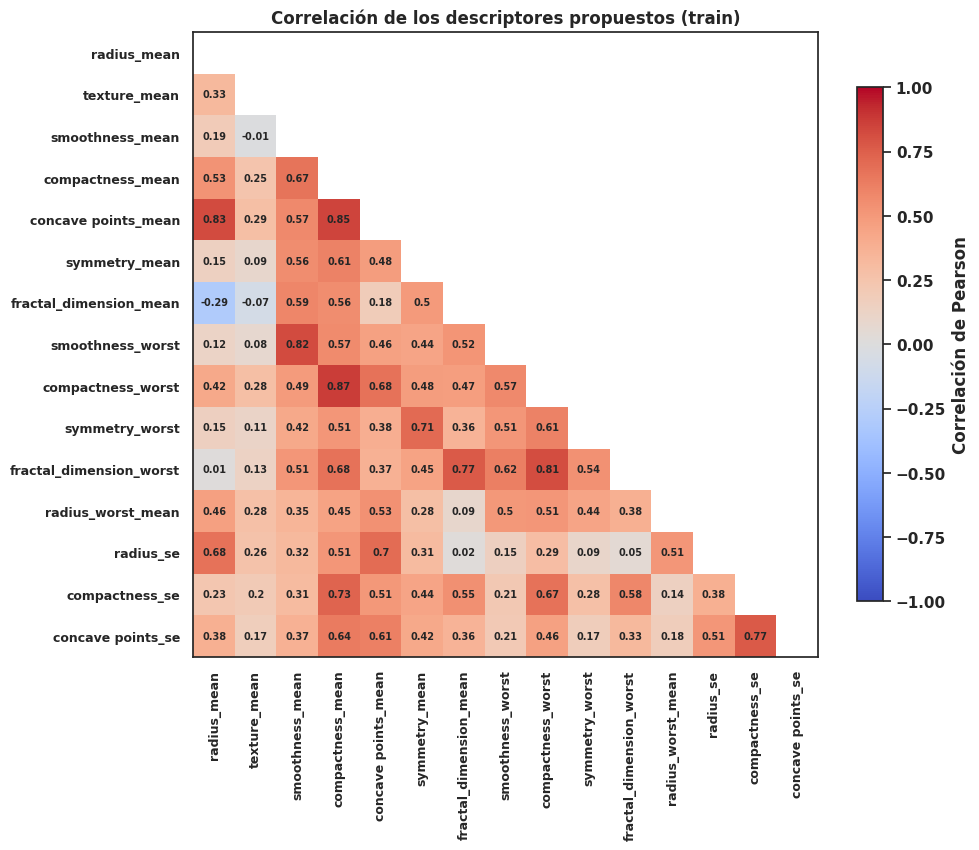

In [ ]:
# Heatmap de correlación de los 15 descriptores propuestos (train)
corr_fe = X_train_fe.corr()
mascara = np.triu(np.ones_like(corr_fe, dtype=bool))
corr_plot = corr_fe.where(~mascara)

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr_plot.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_fe)))
ax.set_xticklabels(corr_fe.columns, rotation=90, fontsize=9)
ax.set_yticks(range(len(corr_fe)))
ax.set_yticklabels(corr_fe.columns, fontsize=9)
for f in range(len(corr_fe)):
    for c2 in range(f):
        ax.text(c2, f, str(round(corr_fe.values[f, c2], 2)), ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8, label="Correlación de Pearson")
ax.set_title("Correlación de los descriptores propuestos (train)")
fig.tight_layout()
guardar(fig, "fe_correlacion")
plt.show()

Imputacion de los dato faltantes para datos de validación

In [ ]:
import pandas as pd
from google.colab import files

# 1) Cargar validación
files.upload()                                   # sube bc_val.csv
df_val = pd.read_csv("bc_val.csv")

# 2) Separar id, etiqueta y variables
y_val = df_val["diagnosis"].map({"B": 0, "M": 1})    # mismo mapeo que en train
X_val = df_val.drop(columns=["id", "diagnosis"])

# 3) Imputación por mediana con estadísticos del TRAIN
medianas_train = X_train.median()
X_val_imp = X_val[X_train.columns].fillna(medianas_train)

# Equivalente con SimpleImputer (si lo usaste en train, reutiliza el mismo objeto):
# X_val_imp = pd.DataFrame(
#     imputer.transform(X_val[X_train.columns]),
#     columns=X_train.columns, index=X_val.index
# )

# 4) Verificación
print("Faltantes antes  :", X_val.isna().sum().sum())
print("Faltantes después:", X_val_imp.isna().sum().sum())

Saving bc_val.csv to bc_val (2).csv
Faltantes antes  : 0
Faltantes después: 0


TRABAJO CON DATOS DE VALIDACION: EDA
Gráficos de barras para variables categóricas

            n     %
diagnosis          
B          36  63.2
M          21  36.8


/tmp/ipykernel_1111/4043133184.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_val, x="diagnosis", order=["B", "M"], palette="Set2")


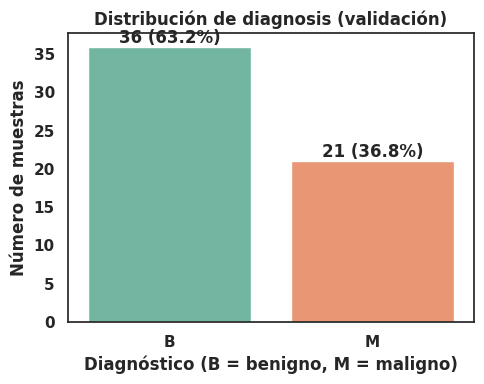

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar validación (omite si ya tienes df_val)
# from google.colab import files
# files.upload()
df_val = pd.read_csv("bc_val.csv")

# Conteo y porcentaje por clase
conteo = df_val["diagnosis"].value_counts()
porcentaje = df_val["diagnosis"].value_counts(normalize=True) * 100
print(pd.DataFrame({"n": conteo, "%": porcentaje.round(1)}))

# Gráfico de barras
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df_val, x="diagnosis", order=["B", "M"], palette="Set2")

# Etiquetas con cantidad y porcentaje sobre cada barra
for i, clase in enumerate(["B", "M"]):
    ax.text(i, conteo[clase] + 0.5,
            f"{conteo[clase]} ({porcentaje[clase]:.1f}%)",
            ha="center")

ax.set_title("Distribución de diagnosis (validación)")
ax.set_xlabel("Diagnóstico (B = benigno, M = maligno)")
ax.set_ylabel("Número de muestras")
plt.tight_layout()
plt.show()

EDA: BOXPLOT PARA DATOS DE VALIDACION

/tmp/ipykernel_1111/3380439769.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot_val, x="diagnosis", y="radius_mean", palette="Set2")


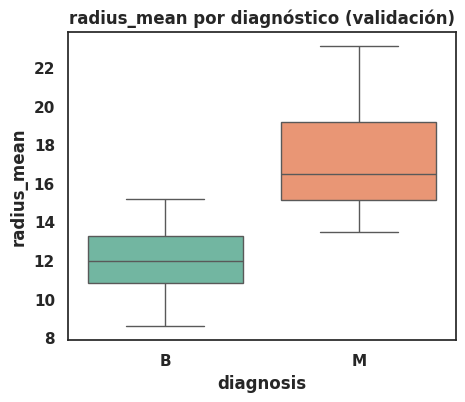

/tmp/ipykernel_1111/3380439769.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3380439769.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3380439769.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3380439769.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in

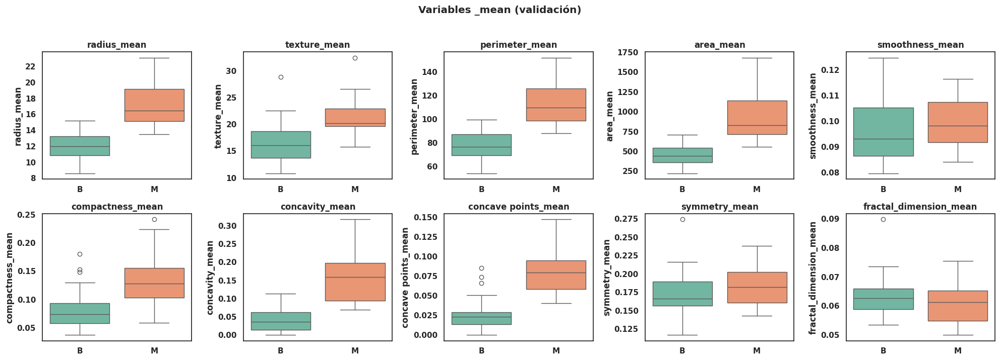

/tmp/ipykernel_1111/3380439769.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3380439769.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3380439769.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3380439769.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in

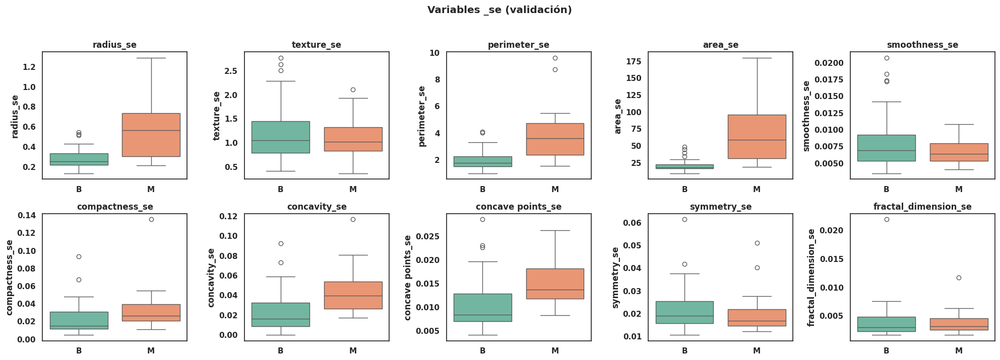

/tmp/ipykernel_1111/3380439769.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3380439769.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3380439769.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3380439769.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in

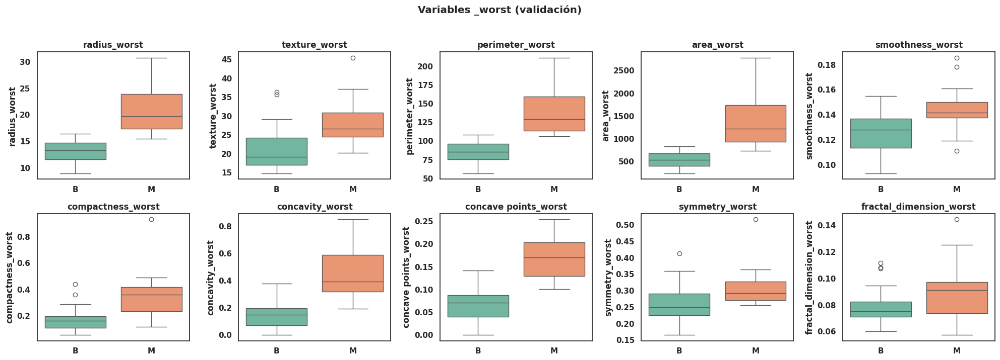

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar validación (omite estas líneas si ya tienes df_val)
# from google.colab import files
# files.upload()
df_val = pd.read_csv("bc_val.csv")

# Variables numéricas + diagnóstico como categoría
df_plot_val = df_val.drop(columns=["id"])

# 1) Una sola variable
plt.figure(figsize=(5, 4))
sns.boxplot(data=df_plot_val, x="diagnosis", y="radius_mean", palette="Set2")
plt.title("radius_mean por diagnóstico (validación)")
plt.show()

# 2) Grid por grupo de variables (_mean, _se, _worst)
def boxplots_grupo(df, sufijo, ncols=5):
    cols = [c for c in df.columns if c.endswith(sufijo)]
    nrows = -(-len(cols) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows))
    axes = axes.ravel()
    for ax, col in zip(axes, cols):
        sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
        ax.set_title(col)
        ax.set_xlabel("")
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.suptitle(f"Variables {sufijo} (validación)", y=1.02)
    plt.tight_layout()
    plt.show()

boxplots_grupo(df_plot_val, "_mean")
boxplots_grupo(df_plot_val, "_se")
boxplots_grupo(df_plot_val, "_worst")

PAIR PLOTS POR GRUPO

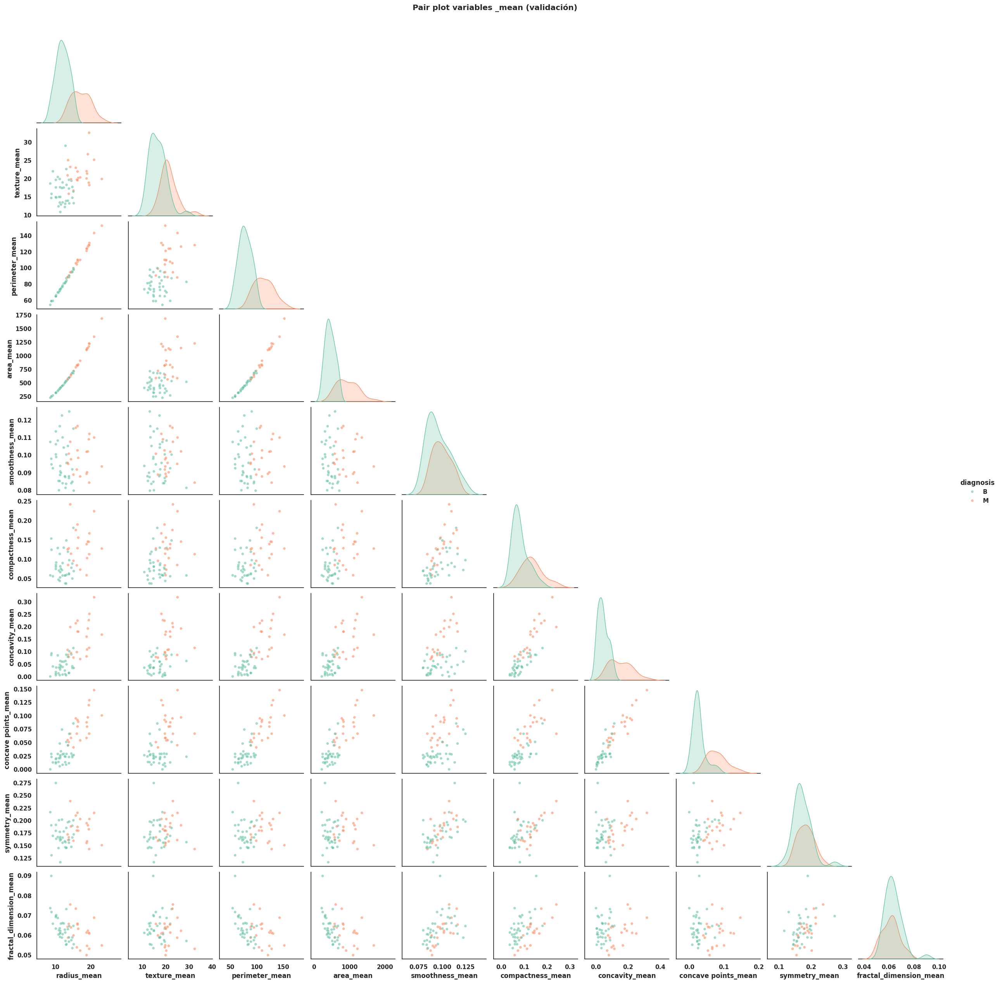

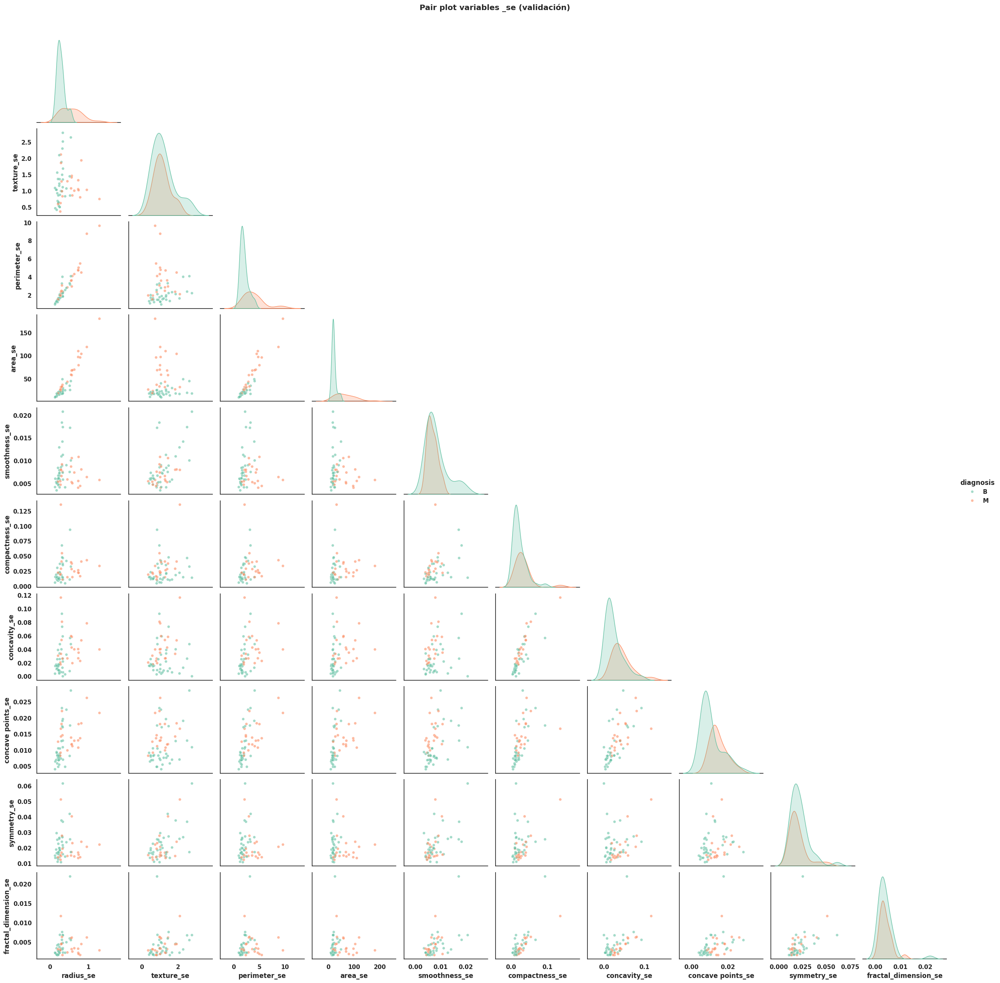

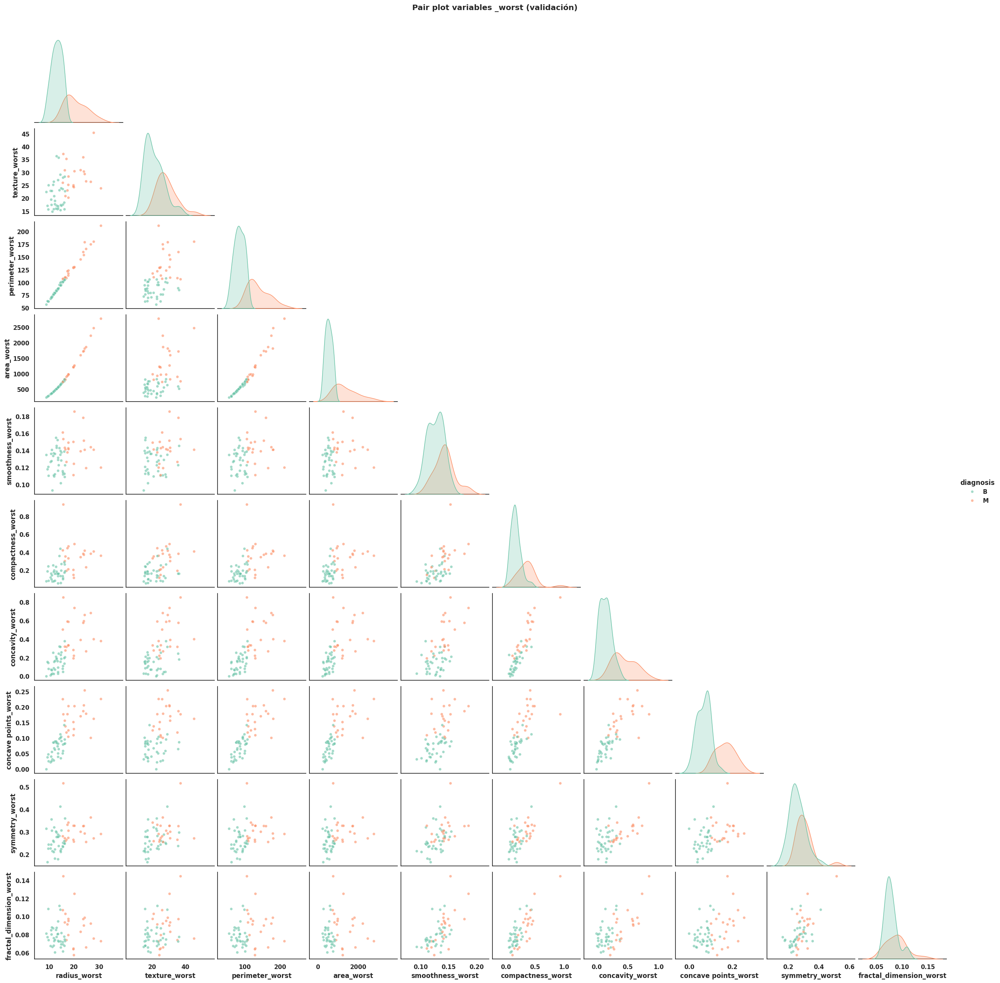

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar validación (omite si ya tienes df_val)
# from google.colab import files
# files.upload()
df_val = pd.read_csv("bc_val.csv")
df_plot_val = df_val.drop(columns=["id"])

def pairplot_grupo(df, sufijo, hue="diagnosis"):
    cols = [c for c in df.columns if c.endswith(sufijo)]
    g = sns.pairplot(
        df[cols + [hue]],
        hue=hue,
        hue_order=["B", "M"],
        palette="Set2",
        diag_kind="kde",          # densidad en la diagonal
        corner=True,              # solo triángulo inferior (más liviano)
        plot_kws={"alpha": 0.6, "s": 25},
    )
    g.figure.suptitle(f"Pair plot variables {sufijo} (validación)", y=1.02)
    plt.show()

pairplot_grupo(df_plot_val, "_mean")
pairplot_grupo(df_plot_val, "_se")
pairplot_grupo(df_plot_val, "_worst")

grafico para pares de prescriptores mas relacionados

           var1            var2  correlacion
    radius_mean  perimeter_mean     0.998053
   radius_worst perimeter_worst     0.994150
    radius_mean       area_mean     0.990304
 perimeter_mean       area_mean     0.989187
   radius_worst      area_worst     0.988042
      area_mean perimeter_worst     0.981990
perimeter_worst      area_worst     0.981752
      area_mean    radius_worst     0.978867
 perimeter_mean perimeter_worst     0.976378


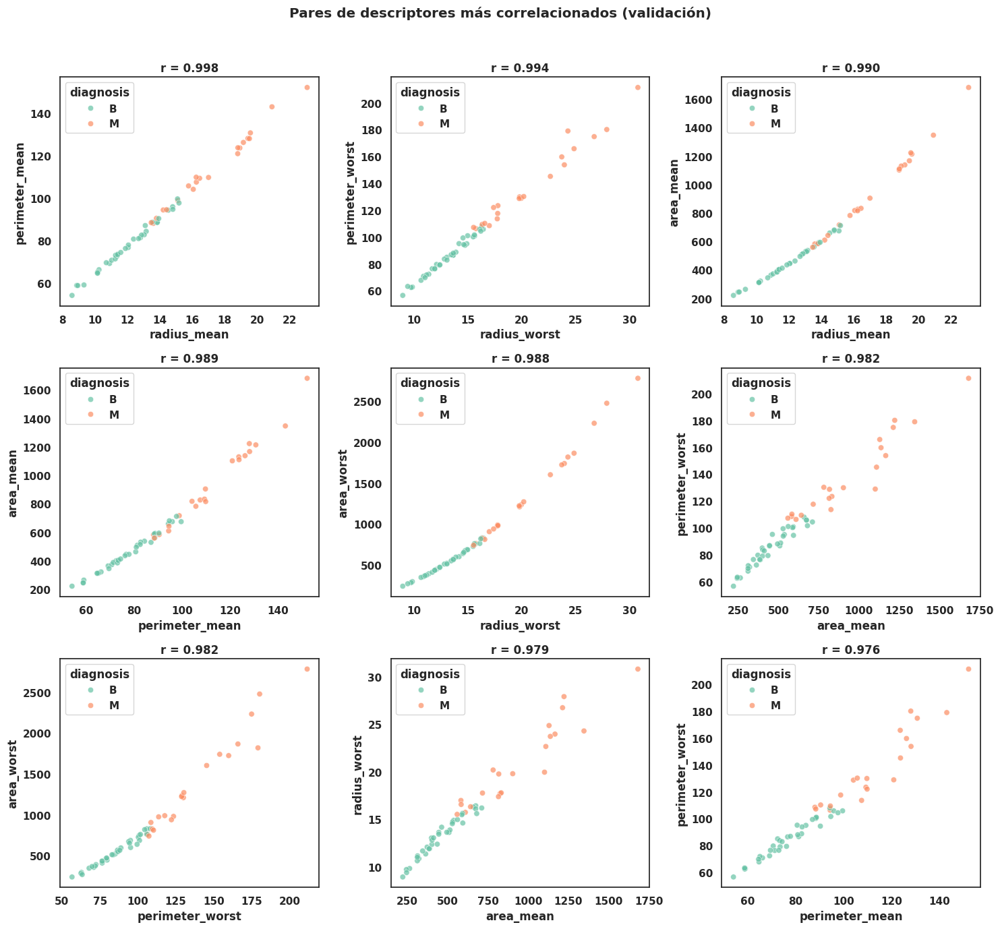

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar validación (omite si ya tienes df_val)
df_val = pd.read_csv("bc_val.csv")
df_plot_val = df_val.drop(columns=["id"])
X_val = df_plot_val.drop(columns=["diagnosis"])

# 1) Matriz de correlación y pares únicos (triángulo superior)
corr = X_val.corr()
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pares = (
    corr.where(mask)
    .stack()
    .rename("correlacion")
    .reset_index()
    .rename(columns={"level_0": "var1", "level_1": "var2"})
)
pares["abs_corr"] = pares["correlacion"].abs()
top_pares = pares.sort_values("abs_corr", ascending=False).head(9)   # cambia 9 por los que quieras
print(top_pares[["var1", "var2", "correlacion"]].to_string(index=False))

# 2) Gráficos de dispersión de los pares más correlacionados
n = len(top_pares)
ncols = 3
nrows = -(-n // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, (_, fila) in zip(axes, top_pares.iterrows()):
    sns.scatterplot(
        data=df_plot_val, x=fila["var1"], y=fila["var2"],
        hue="diagnosis", hue_order=["B", "M"], palette="Set2",
        alpha=0.7, ax=ax
    )
    ax.set_title(f"r = {fila['correlacion']:.3f}")

for ax in axes[n:]:
    ax.axis("off")

plt.suptitle("Pares de descriptores más correlacionados (validación)", y=1.02)
plt.tight_layout()
plt.show()

scatter plot de un par especifico


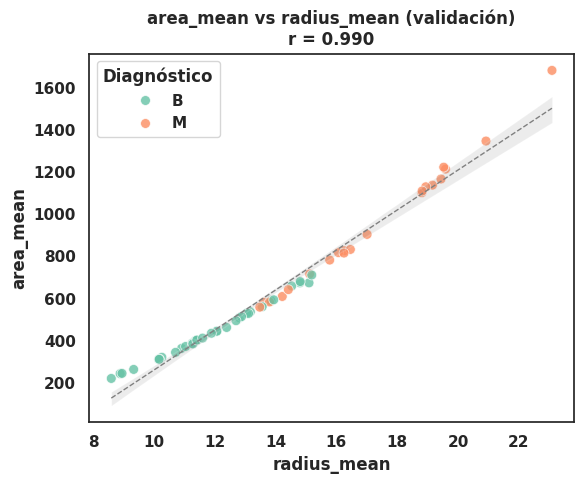

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar validación (omite si ya tienes df_val)
df_val = pd.read_csv("bc_val.csv")

# Par específico a graficar (cambia los nombres)
var_x = "radius_mean"
var_y = "area_mean"

# Correlación del par
r = df_val[var_x].corr(df_val[var_y])

plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=df_val, x=var_x, y=var_y,
    hue="diagnosis", hue_order=["B", "M"],
    palette="Set2", alpha=0.8, s=50
)

# Línea de tendencia global (opcional; quítala si no la quieres)
sns.regplot(
    data=df_val, x=var_x, y=var_y,
    scatter=False, color="gray", line_kws={"linestyle": "--", "linewidth": 1}
)

plt.title(f"{var_y} vs {var_x} (validación)\nr = {r:.3f}")
plt.xlabel(var_x)
plt.ylabel(var_y)
plt.legend(title="Diagnóstico")
plt.tight_layout()
plt.show()

heatmap de correlacion de variables continuas

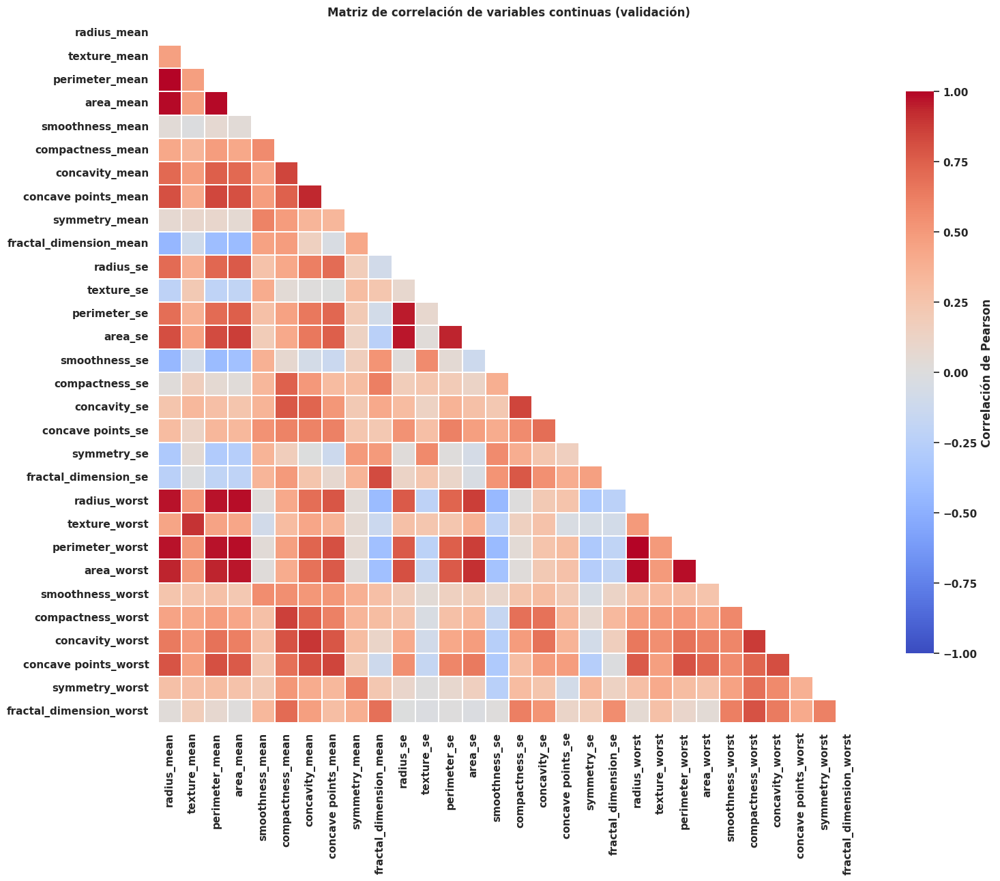

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar validación (omite si ya tienes df_val)
df_val = pd.read_csv("bc_val.csv")

# Solo variables continuas (sin id ni diagnosis)
X_val = df_val.drop(columns=["id", "diagnosis"])

# Matriz de correlación de Pearson
corr = X_val.corr(method="pearson")

# Máscara para mostrar solo el triángulo inferior
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(16, 13))
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1, vmax=1, center=0,
    square=True,
    linewidths=0.3,
    annot=False,                 # pon True para ver los valores (se satura con 30 variables)
    cbar_kws={"label": "Correlación de Pearson", "shrink": 0.8}
)
plt.title("Matriz de correlación de variables continuas (validación)")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Correlacion de Spearman

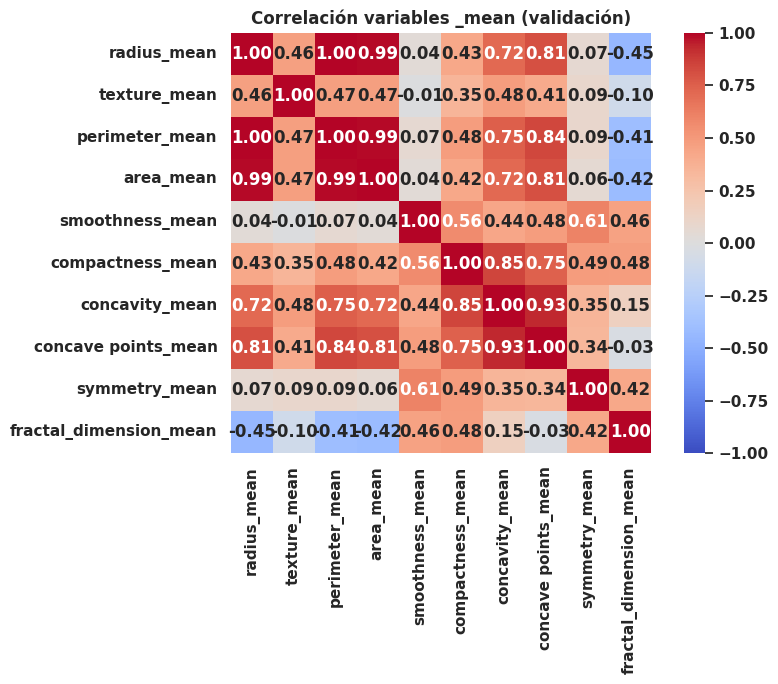

In [ ]:
# Con los valores numéricos, para un grupo de variables (más legible)
cols_mean = [c for c in X_val.columns if c.endswith("_mean")]
plt.figure(figsize=(9, 7))
sns.heatmap(X_val[cols_mean].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True)
plt.title("Correlación variables _mean (validación)")
plt.tight_layout()
plt.show()

# Correlación de Spearman (más robusta a outliers y relaciones no lineales)
corr_sp = X_val.corr(method="spearman")

TRABAJO CON DATOS DE TESTEO:
Imputacion

In [ ]:
import pandas as pd
from google.colab import files

# 1) Cargar test
files.upload()                                   # sube bc_test.csv
df_test = pd.read_csv("bc_test.csv")

# 2) Separar id, etiqueta y variables
y_test = df_test["diagnosis"].map({"B": 0, "M": 1})   # mismo mapeo que en train
X_test = df_test.drop(columns=["id", "diagnosis"])

# 3) Imputación por mediana con estadísticos del TRAIN
medianas_train = X_train.median()
X_test_imp = X_test[X_train.columns].fillna(medianas_train)

# Equivalente con SimpleImputer (si lo usaste en train, reutiliza el mismo objeto ya ajustado):
# X_test_imp = pd.DataFrame(
#     imputer.transform(X_test[X_train.columns]),
#     columns=X_train.columns, index=X_test.index
# )

# 4) Verificación
print("Faltantes antes  :", X_test.isna().sum().sum())
print("Faltantes después:", X_test_imp.isna().sum().sum())
print("Shape test imputado:", X_test_imp.shape)

Saving bc_test.csv to bc_test (1).csv
Faltantes antes  : 0
Faltantes después: 0
Shape test imputado: (57, 30)


EDA:
grafico de barra para variables categoricas


            n     %
diagnosis          
B          36  63.2
M          21  36.8


/tmp/ipykernel_1111/4153503549.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_test, x="diagnosis", order=["B", "M"], palette="Set2")


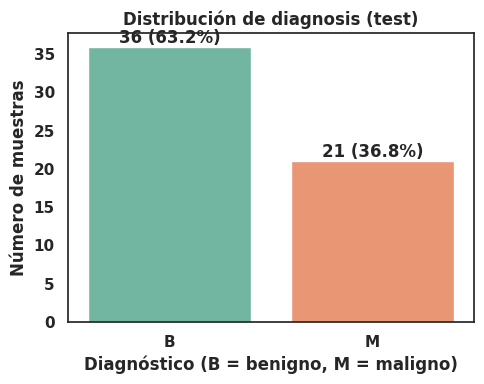

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar test (omite si ya tienes df_test)
# from google.colab import files
# files.upload()
df_test = pd.read_csv("bc_test.csv")

# Conteo y porcentaje por clase
conteo = df_test["diagnosis"].value_counts()
porcentaje = df_test["diagnosis"].value_counts(normalize=True) * 100
print(pd.DataFrame({"n": conteo, "%": porcentaje.round(1)}))

# Gráfico de barras
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df_test, x="diagnosis", order=["B", "M"], palette="Set2")

# Etiquetas con cantidad y porcentaje sobre cada barra
for i, clase in enumerate(["B", "M"]):
    ax.text(i, conteo[clase] + 0.5,
            f"{conteo[clase]} ({porcentaje[clase]:.1f}%)",
            ha="center")

ax.set_title("Distribución de diagnosis (test)")
ax.set_xlabel("Diagnóstico (B = benigno, M = maligno)")
ax.set_ylabel("Número de muestras")
plt.tight_layout()
plt.show()

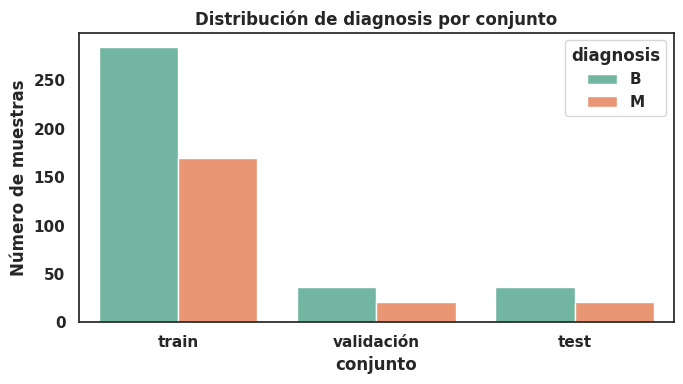

In [ ]:
df_all = pd.concat([
    df_train.assign(conjunto="train"),   # df_train: tu dataframe de entrenamiento con la columna diagnosis
    df_val.assign(conjunto="validación"),
    df_test.assign(conjunto="test"),
])

plt.figure(figsize=(7, 4))
sns.countplot(data=df_all, x="conjunto", hue="diagnosis",
              hue_order=["B", "M"], palette="Set2",
              order=["train", "validación", "test"])
plt.title("Distribución de diagnosis por conjunto")
plt.ylabel("Número de muestras")
plt.tight_layout()
plt.show()

boxplot para variables categoricas


/tmp/ipykernel_1111/3579639644.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot_test, x="diagnosis", y="radius_mean", palette="Set2")


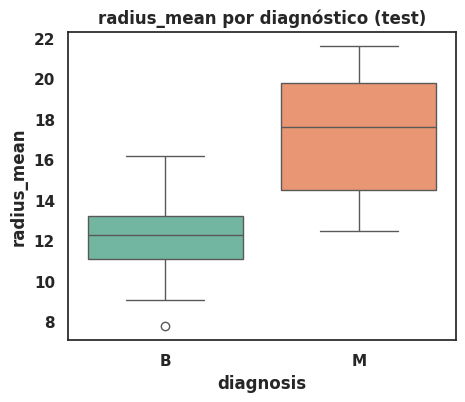

/tmp/ipykernel_1111/3579639644.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3579639644.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3579639644.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3579639644.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in

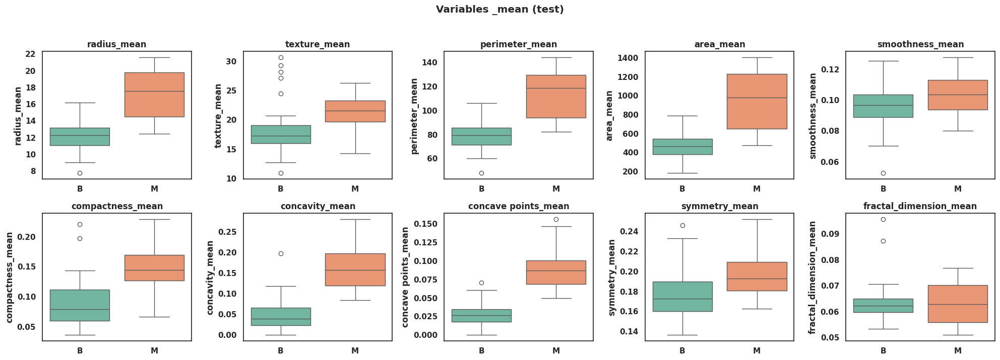

/tmp/ipykernel_1111/3579639644.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3579639644.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3579639644.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3579639644.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in

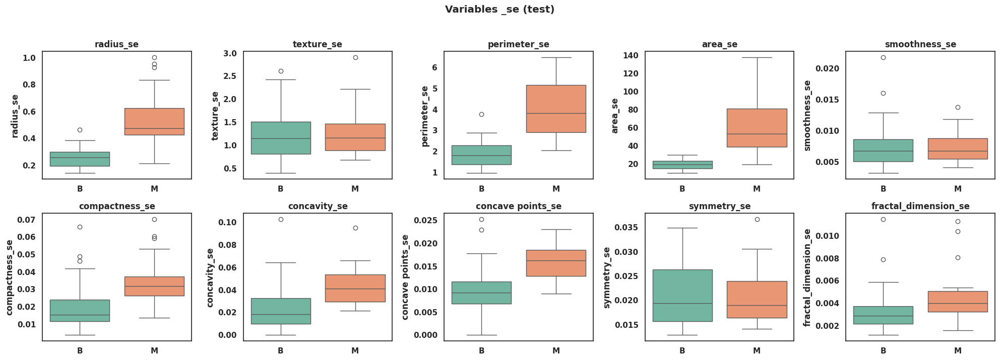

/tmp/ipykernel_1111/3579639644.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3579639644.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3579639644.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
/tmp/ipykernel_1111/3579639644.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in

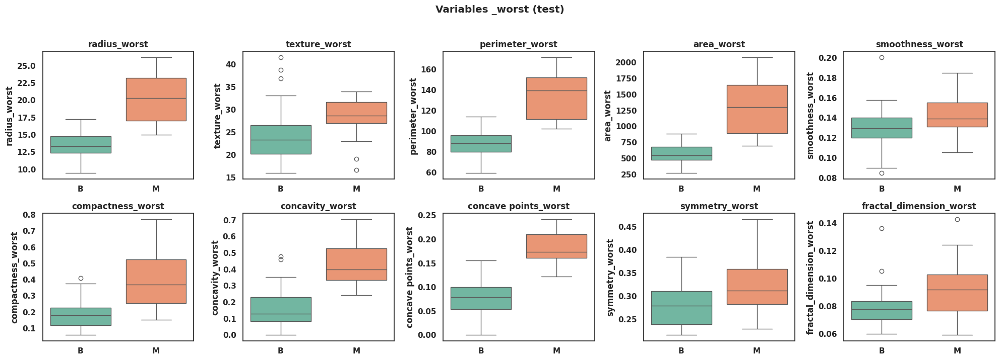

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar test (omite si ya tienes df_test)
# from google.colab import files
# files.upload()
df_test = pd.read_csv("bc_test.csv")

# Variables numéricas + diagnóstico como categoría
df_plot_test = df_test.drop(columns=["id"])

# 1) Una sola variable
plt.figure(figsize=(5, 4))
sns.boxplot(data=df_plot_test, x="diagnosis", y="radius_mean", palette="Set2")
plt.title("radius_mean por diagnóstico (test)")
plt.show()

# 2) Grid por grupo de variables (_mean, _se, _worst)
def boxplots_grupo(df, sufijo, ncols=5):
    cols = [c for c in df.columns if c.endswith(sufijo)]
    nrows = -(-len(cols) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows))
    axes = axes.ravel()
    for ax, col in zip(axes, cols):
        sns.boxplot(data=df, x="diagnosis", y=col, palette="Set2", ax=ax)
        ax.set_title(col)
        ax.set_xlabel("")
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.suptitle(f"Variables {sufijo} (test)", y=1.02)
    plt.tight_layout()
    plt.show()

boxplots_grupo(df_plot_test, "_mean")
boxplots_grupo(df_plot_test, "_se")
boxplots_grupo(df_plot_test, "_worst")

pair plots por grupo


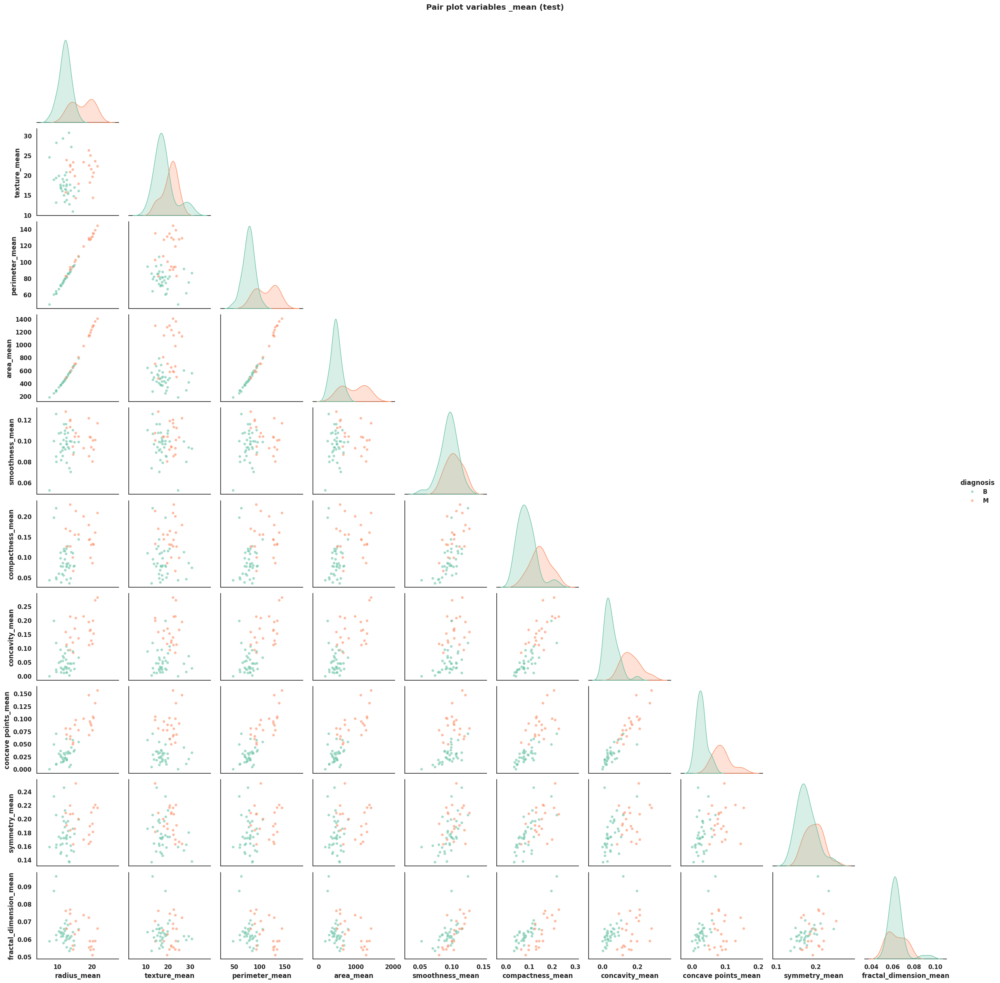

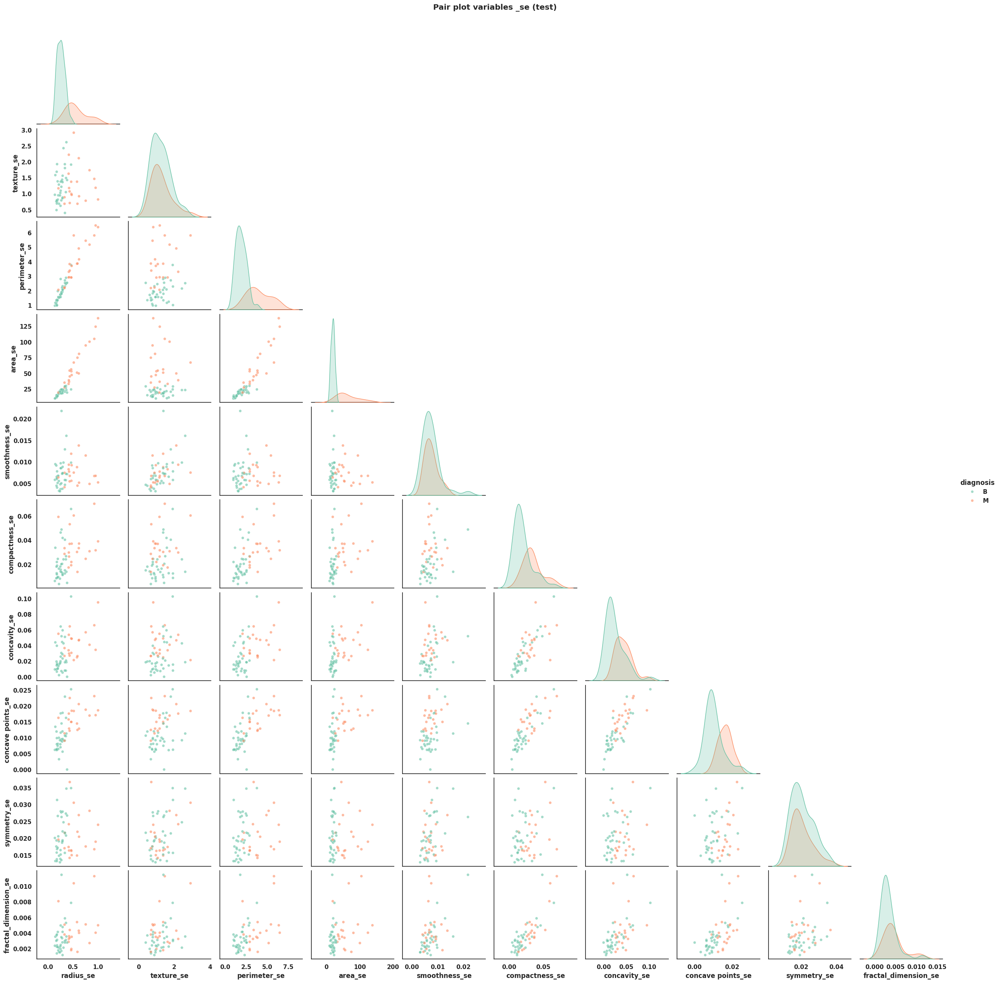

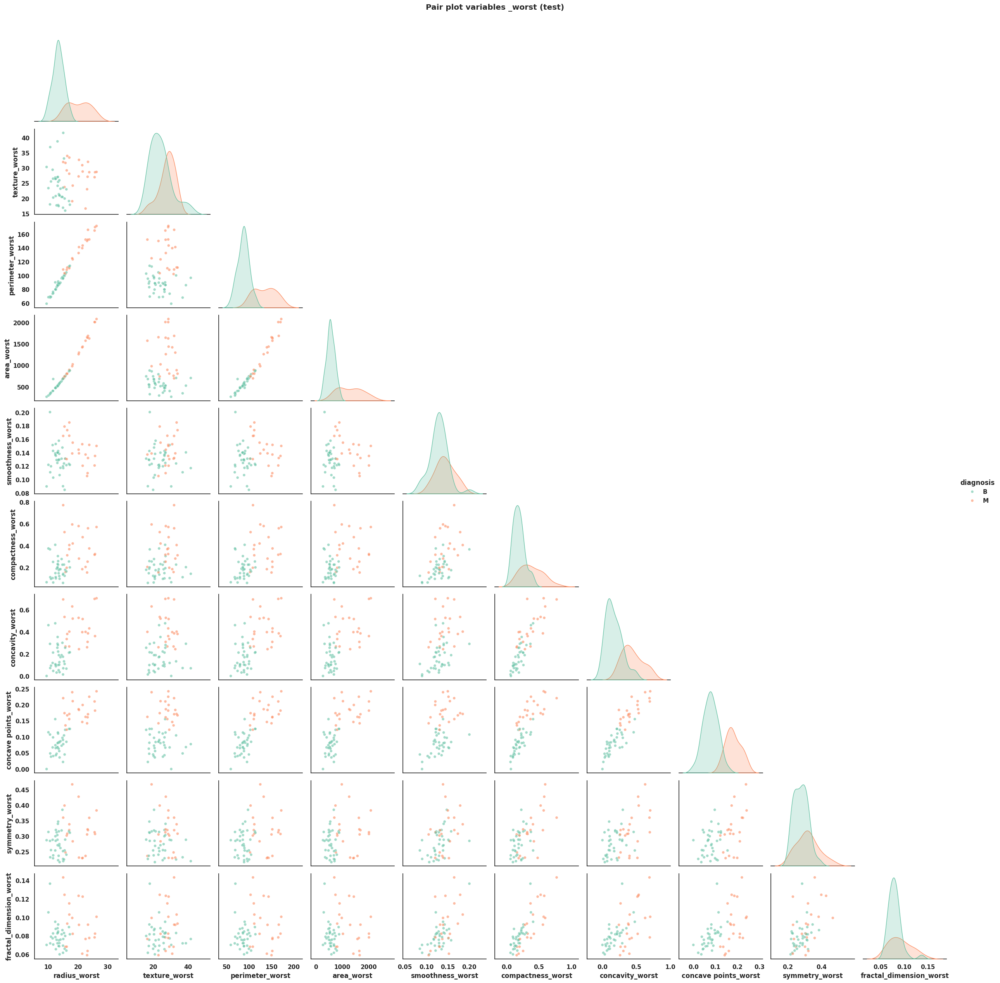

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar test (omite si ya tienes df_test)
# from google.colab import files
# files.upload()
df_test = pd.read_csv("bc_test.csv")
df_plot_test = df_test.drop(columns=["id"])

def pairplot_grupo(df, sufijo, hue="diagnosis"):
    cols = [c for c in df.columns if c.endswith(sufijo)]
    g = sns.pairplot(
        df[cols + [hue]],
        hue=hue,
        hue_order=["B", "M"],
        palette="Set2",
        diag_kind="kde",          # densidad en la diagonal
        corner=True,              # solo triángulo inferior (más liviano)
        plot_kws={"alpha": 0.6, "s": 25},
    )
    g.figure.suptitle(f"Pair plot variables {sufijo} (test)", y=1.02)
    plt.show()

pairplot_grupo(df_plot_test, "_mean")
pairplot_grupo(df_plot_test, "_se")
pairplot_grupo(df_plot_test, "_worst")

grafico para pares de drescriptores mas relacionados


           var1            var2  correlacion
    radius_mean  perimeter_mean     0.998136
   radius_worst perimeter_worst     0.993316
    radius_mean       area_mean     0.992665
 perimeter_mean       area_mean     0.990961
   radius_worst      area_worst     0.988389
perimeter_worst      area_worst     0.979779
 perimeter_mean    radius_worst     0.976013
    radius_mean    radius_worst     0.975045
 perimeter_mean perimeter_worst     0.974966


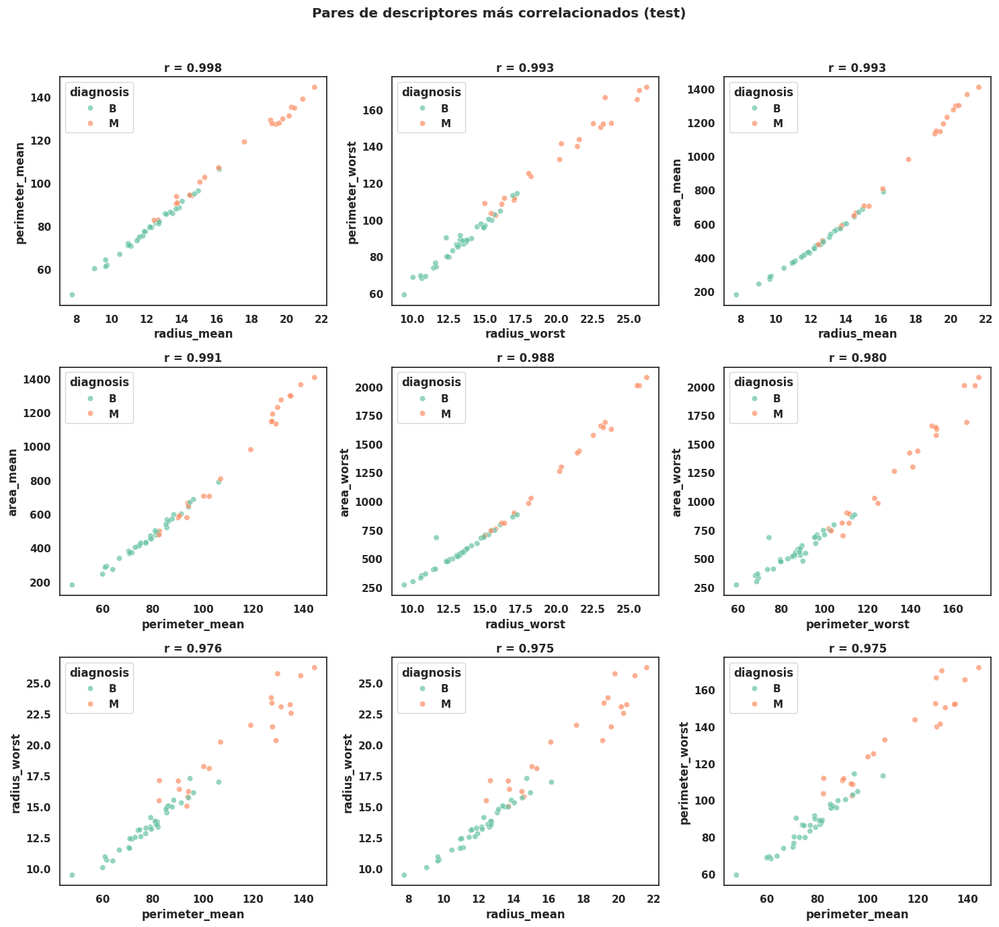

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar test (omite si ya tienes df_test)
df_test = pd.read_csv("bc_test.csv")
df_plot_test = df_test.drop(columns=["id"])
X_test = df_plot_test.drop(columns=["diagnosis"])

# 1) Matriz de correlación y pares únicos (triángulo superior)
corr = X_test.corr()
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pares = (
    corr.where(mask)
    .stack()
    .rename("correlacion")
    .reset_index()
    .rename(columns={"level_0": "var1", "level_1": "var2"})
)
pares["abs_corr"] = pares["correlacion"].abs()
top_pares = pares.sort_values("abs_corr", ascending=False).head(9)   # cambia 9 por los que quieras
print(top_pares[["var1", "var2", "correlacion"]].to_string(index=False))

# 2) Gráficos de dispersión de los pares más correlacionados
n = len(top_pares)
ncols = 3
nrows = -(-n // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, (_, fila) in zip(axes, top_pares.iterrows()):
    sns.scatterplot(
        data=df_plot_test, x=fila["var1"], y=fila["var2"],
        hue="diagnosis", hue_order=["B", "M"], palette="Set2",
        alpha=0.7, ax=ax
    )
    ax.set_title(f"r = {fila['correlacion']:.3f}")

for ax in axes[n:]:
    ax.axis("off")

plt.suptitle("Pares de descriptores más correlacionados (test)", y=1.02)
plt.tight_layout()
plt.show()

scatter plot de un par especifico


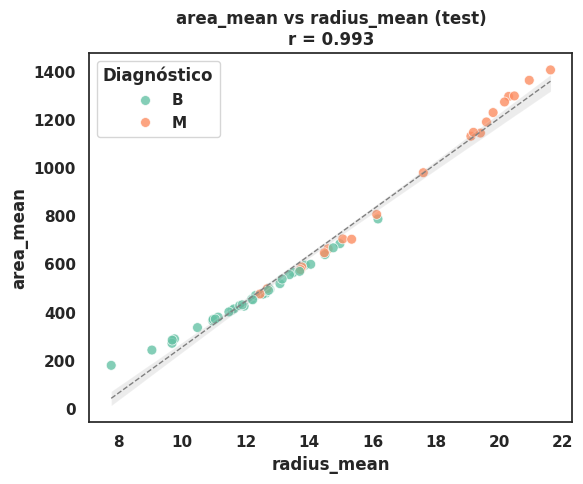

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar test (omite si ya tienes df_test)
df_test = pd.read_csv("bc_test.csv")

# Par específico a graficar (cambia los nombres)
var_x = "radius_mean"
var_y = "area_mean"

# Correlación del par
r = df_test[var_x].corr(df_test[var_y])

plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=df_test, x=var_x, y=var_y,
    hue="diagnosis", hue_order=["B", "M"],
    palette="Set2", alpha=0.8, s=50
)

# Línea de tendencia global (opcional; quítala si no la quieres)
sns.regplot(
    data=df_test, x=var_x, y=var_y,
    scatter=False, color="gray", line_kws={"linestyle": "--", "linewidth": 1}
)

plt.title(f"{var_y} vs {var_x} (test)\nr = {r:.3f}")
plt.xlabel(var_x)
plt.ylabel(var_y)
plt.legend(title="Diagnóstico")
plt.tight_layout()
plt.show()

heatmap de correlacion de variables continuas

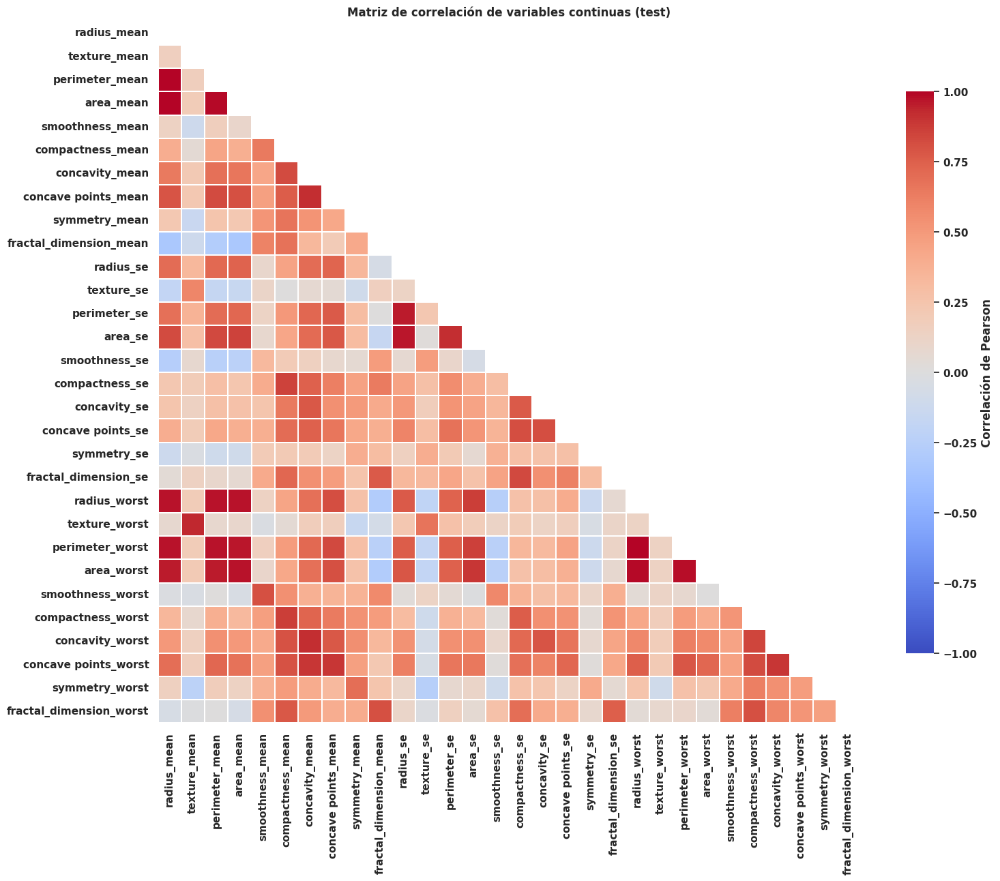

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar test (omite si ya tienes df_test)
df_test = pd.read_csv("bc_test.csv")

# Solo variables continuas (sin id ni diagnosis)
X_test = df_test.drop(columns=["id", "diagnosis"])

# Matriz de correlación de Pearson
corr = X_test.corr(method="pearson")

# Máscara para mostrar solo el triángulo inferior
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(16, 13))
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1, vmax=1, center=0,
    square=True,
    linewidths=0.3,
    annot=False,                 # pon True para ver los valores (se satura con 30 variables)
    cbar_kws={"label": "Correlación de Pearson", "shrink": 0.8}
)
plt.title("Matriz de correlación de variables continuas (test)")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Correlación de Spearman

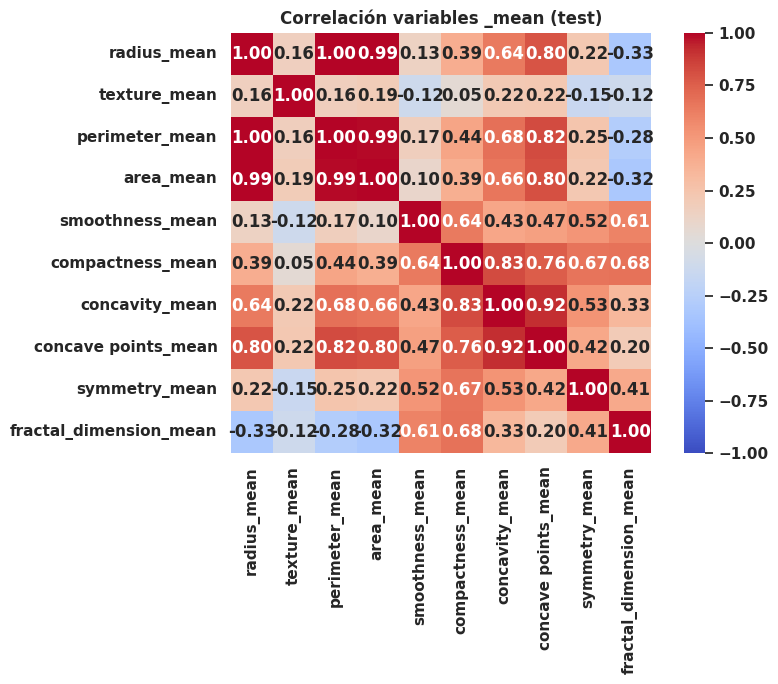

In [ ]:
# Con valores numéricos para un grupo de variables (más legible)
cols_mean = [c for c in X_test.columns if c.endswith("_mean")]
plt.figure(figsize=(9, 7))
sns.heatmap(X_test[cols_mean].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True)
plt.title("Correlación variables _mean (test)")
plt.tight_layout()
plt.show()

# Correlación de Spearman (más robusta a outliers y relaciones no lineales)
corr_sp = X_test.corr(method="spearman")